# Analyse

Le fichier `goods_receipts.csv` contient les réceptions de marchandises enregistrées dans l'ERP de Meridian. Chaque ligne est une livraison arrivée sur un site, avec la commande d'origine, la date, le site, le fournisseur, la quantité, le lot, le résultat de l'inspection, l'emplacement de stockage et le statut.

---
## Configuration

In [1]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Racine du projet = le premier dossier parent qui contient data/logistics
project_root = next(
	(path for path in [Path.cwd(), *Path.cwd().parents]
	 if (path / "data" / "logistics").is_dir()),
	Path.cwd(),
)
# Le dossier utils peut être à la racine ou dans un sous-dossier (ex. notebooks/utils)
dossier_utils = next(
	(p for p in [project_root, *project_root.glob("*"), *project_root.glob("*/*")]
	 if (p / "utils" / "variable_analysis.py").is_file()),
	None,
)
if dossier_utils is None:
	raise FileNotFoundError(f"Dossier utils introuvable sous {project_root}")
if str(dossier_utils) not in sys.path:
	sys.path.insert(0, str(dossier_utils))

from utils.variable_analysis import analyser_variables
from utils.correlation_matrices import matrice_correlation, matrice_cramer

DATA = project_root / "data" / "logistics"
pd.set_option("display.width", 200)

---
## 1. Découverte de la table

### 1.1 Lecture brute et dictionnaire des données

On lit d'abord le fichier en texte (`dtype=str`) pour voir les valeurs telles qu'elles ont été saisies, sans conversion automatique.

In [2]:
brut = pd.read_csv(DATA / "goods_receipts.csv", dtype=str, keep_default_na=False)
print("Dimensions brutes :", brut.shape)

dico = pd.read_csv(project_root / "data" / "data_dictionary.csv")
dico = dico[dico.iloc[:, 2] == "goods_receipts.csv"].iloc[:, 3:].reset_index(drop=True)
dico.columns = ["variable", "type_dictionnaire", "role_cle", "description", "exemple"]
dico

Dimensions brutes : (612, 12)


,variable,type_dictionnaire,role_cle,description,exemple
0,receipt_number,identifier,primary_or_composite_key,Receipt number.,RCV-2014-00001
1,purchase_order_number,identifier,non_key,Purchase order number.,PO-2014-00001
2,purchase_order_line,categorical_or_text,non_key,Purchase order line.,1
3,receipt_date,date_or_datetime,non_key,Receipt date.,2014-07-08
4,receiving_facility_code,identifier,non_key,Receiving facility code.,FCL-1007
5,supplier_partner_code,identifier,non_key,Supplier partner code.,BP-30078
6,received_quantity,numeric,non_key,Received quantity.,73
7,received_unit,categorical_or_text,non_key,Received unit.,case
8,batch_reference,identifier,non_key,Batch reference.,B-2014-44545
9,inspection_status,categorical_or_text,non_key,Inspection status.,held


In [3]:
brut.head(8)

,receipt_number,purchase_order_number,purchase_order_line,receipt_date,receiving_facility_code,supplier_partner_code,received_quantity,received_unit,batch_reference,inspection_status,storage_location_code,receipt_status
0,RCV-2014-00001,PO-2014-00001,1,2014-07-08,FCL-1007,BP-30078,73,case,B-2014-44545,held,BIN-35,quality_hold
1,RCV-2015-00002,PO-2015-00001,1,2015-02-02,FCL-1010,BP-30068,0.9,service,B-2015-58495,accepted,BIN-36,posted
2,RCV-2015-00003,PO-2015-00002,1,2015-02-28,FCL-1030,BP-30066,1,service,B-2015-48474,held,BIN-17,quality_hold
3,RCV-2015-00004,PO-2015-00003,1,2015-03-02,FCL-1010,BP-30080,3,pack,B-2015-71913,accepted,BIN-16,posted
4,RCV-2015-00005,PO-2015-00004,1,2015-02-21,FCL-1022,BP-30021,1,grant,B-2015-31154,accepted,BIN-42,posted
5,RCV-2015-00006,PO-2015-00005,1,2015-03-13,FCL-1009,BP-30039,19,pallet,B-2015-15126,accepted,BIN-22,posted
6,RCV-2015-00007,PO-2015-00006,1,2015-03-10,FCL-1011,BP-30037,3,unit,B-2015-57188,accepted,BIN-03,posted
7,RCV-2015-00008,PO-2015-00007,1,2015-04-09,FCL-1019,BP-30039,1,service,B-2015-63040,accepted,BIN-32,posted


Une ligne = une réception (une livraison, ou un service rendu), rattachée à une ligne de commande. Le fichier fait 612 lignes et 12 colonnes.

La table vient de l'ERP de Meridian BioLogistics (`BP-30078`). C'est important à garder en tête : ce sont des données déclarées par l'entreprise elle-même, donc on voit ce que Meridian a enregistré, ce qui n'est pas forcément ce qui s'est passé.

La clé est `receipt_number`, et trois colonnes permettent de faire le lien avec les autres tables : la commande (`purchase_order_number`), le site (`receiving_facility_code`) et le fournisseur (`supplier_partner_code`). Dans les premières lignes on remarque déjà des choses un peu bizarres, comme 0,9 service, beaucoup d'unités différentes, ou une réception bloquée en qualité (`quality_hold`).

### 1.2 Type de chaque colonne

Pour chaque colonne on regarde le nombre de valeurs différentes, la part de vides et quelques exemples, ce qui suffit pour savoir à quoi on a affaire.

In [4]:
apercu = pd.DataFrame({
    "valeurs_distinctes": brut.nunique(),
    "vides": (brut.apply(lambda s: s.str.strip()) == "").sum(),
    "exemples": brut.apply(lambda s: list(s.drop_duplicates().head(4))),
})
apercu

,valeurs_distinctes,vides,exemples
receipt_number,610,0,"[RCV-2014-00001, RCV-2015-00002, RCV-2015-0000..."
purchase_order_number,610,0,"[PO-2014-00001, PO-2015-00001, PO-2015-00002, ..."
purchase_order_line,1,0,[1]
receipt_date,488,0,"[2014-07-08, 2015-02-02, 2015-02-28, 2015-03-02]"
receiving_facility_code,30,0,"[FCL-1007, FCL-1010, FCL-1030, FCL-1022]"
supplier_partner_code,69,0,"[BP-30078, BP-30068, BP-30066, BP-30080]"
received_quantity,149,0,"[73, 0.9, 1, 3]"
received_unit,9,0,"[case, service, pack, grant]"
batch_reference,610,0,"[B-2014-44545, B-2015-58495, B-2015-48474, B-2..."
inspection_status,4,4,"[held, accepted, conditional, ]"


Le dictionnaire ne donne que quatre types (identifiant, nombre, date, texte), alors on a précisé nous-mêmes :

| Colonne | Type | Remarque |
|---|---|---|
| `receipt_number` | identifiant | 610 valeurs pour 612 lignes, donc des doublons. Contient l'année. |
| `purchase_order_number` | identifiant (lien vers la commande) | une commande = une réception |
| `purchase_order_line` | constante | toujours 1, inutile |
| `receipt_date` | date | écrite de plusieurs façons |
| `receiving_facility_code` | catégorie (lien vers le site) | 30 sites |
| `supplier_partner_code` | catégorie (lien vers le partenaire) | 69 partenaires |
| `received_quantity` | nombre | parfois avec l'unité ou une virgule ; le sens dépend de l'unité |
| `received_unit` | catégorie | 9 unités |
| `batch_reference` | identifiant | un lot par réception |
| `inspection_status` | catégorie ordonnable (`accepted` < `conditional` < `held`) | 4 vides |
| `storage_location_code` | catégorie | 42 emplacements, sans le site |
| `receipt_status` | catégorie | `posted`, `quality_hold`, et une variante `POSTED` |

---
## 2. Nettoyage

On nettoie dans l'ordre : doublons, formats, libellés, puis valeurs manquantes et valeurs bizarres. On ne touche jamais à la table brute `brut`, on travaille sur une copie `gr`.

### 2.1 Doublons

On cherche les lignes en double, les colonnes constantes et les informations qui se répètent.

In [5]:
gr = brut.copy()
for c in gr.columns:
    gr[c] = gr[c].str.strip()

# --- Lignes
doublons = gr[gr.duplicated(keep=False)].sort_values("receipt_number")
print(f"Doublons exacts : {gr.duplicated().sum()} ligne(s) en trop")
print(doublons[["receipt_number", "purchase_order_number", "receipt_date", "received_quantity"]].to_string())
gr = gr.drop_duplicates().reset_index(drop=True)
print(f"Doublons restants sur la clé receipt_number : {gr.receipt_number.duplicated().sum()}")
print(f"Une commande reçue plusieurs fois ? {gr.purchase_order_number.duplicated().sum()} cas")
print("Dimensions après suppression :", gr.shape)

# --- Colonnes
print("\nColonnes constantes :", [c for c in gr.columns if gr[c].nunique() == 1])
annee_rcv = gr.receipt_number.str[4:8]
annee_batch = gr.batch_reference.str[2:6]
print("Année du numéro de réception = année du lot :", (annee_rcv == annee_batch).mean())

Doublons exacts : 2 ligne(s) en trop
     receipt_number purchase_order_number receipt_date received_quantity
35   RCV-2016-00036         PO-2016-00010   2016-04-13                 6
611  RCV-2016-00036         PO-2016-00010   2016-04-13                 6
318  RCV-2022-00319         PO-2022-00007   2022-02-22                30
610  RCV-2022-00319         PO-2022-00007   2022-02-22                30
Doublons restants sur la clé receipt_number : 0
Une commande reçue plusieurs fois ? 0 cas
Dimensions après suppression : (610, 12)

Colonnes constantes : ['purchase_order_line']
Année du numéro de réception = année du lot : 1.0


Il y a deux lignes copiées à l'identique (`RCV-2016-00036` et `RCV-2022-00319`), à la toute fin du fichier. Comme elles sont identiques jusqu'au numéro de lot, ça fait plutôt penser à un double export qu'à une vraie double livraison, donc on les enlève. Il reste 610 lignes et chaque commande n'est reçue qu'une fois.

`purchase_order_line` vaut toujours 1, on la retirera. L'année est écrite à la fois dans le numéro de réception et dans le lot, et c'est toujours la même, ce qui va nous servir pour vérifier les dates.

### 2.2 Formats

Deux colonnes posent problème : la date, écrite de plusieurs façons, et la quantité, parfois suivie de l'unité ou avec une virgule.

In [6]:
# --- Dates : quels formats sont présents ?
iso = gr.receipt_date.str.fullmatch(r"\d{4}-\d{2}-\d{2}")
print(f"Dates au format ISO AAAA-MM-JJ : {iso.sum()} / {len(gr)}")
autres = gr.loc[~iso, ["receipt_number", "receipt_date"]]
# contexte : dates des réceptions voisines (numérotation séquentielle)
autres["date_precedente"] = [gr.receipt_date.iloc[i - 1] for i in autres.index]
autres["date_suivante"] = [gr.receipt_date.iloc[i + 1] if i + 1 < len(gr) else "" for i in autres.index]
print(autres.to_string())

Dates au format ISO AAAA-MM-JJ : 605 / 610
     receipt_number receipt_date date_precedente date_suivante
224  RCV-2020-00225   2020/05/02      2020-05-25    2020-05-24
442  RCV-2023-00443   2023/09/03      2023-06-25    2023-09-17
527  RCV-2024-00528   12/07/2024      2024-07-04    2024-07-07
568  RCV-2025-00569   2025/06/11      2025-06-07    2025-05-22
609  RCV-2025-00610   30/06/2025      2025-06-30              


In [7]:
def convertir_date(s):
    """AAAA-MM-JJ, AAAA/MM/JJ, puis JJ/MM/AAAA (format jour-mois, voir rapport)."""
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d/%m/%Y"):
        d = pd.to_datetime(s, format=fmt, errors="coerce")
        if pd.notna(d):
            return d
    return pd.NaT

gr["receipt_date"] = gr.receipt_date.map(convertir_date)
print("Dates non converties :", gr.receipt_date.isna().sum())
print("Période couverte :", gr.receipt_date.min().date(), "→", gr.receipt_date.max().date())
print("Année du numéro de réception = année de la date :",
      (gr.receipt_number.str[4:8].astype(int) == gr.receipt_date.dt.year).mean())

Dates non converties : 0
Période couverte : 2014-07-08 → 2025-06-30
Année du numéro de réception = année de la date : 1.0


In [8]:
# --- Quantités : valeurs qui ne sont pas un nombre simple
q = gr.received_quantity
non_num = ~q.str.fullmatch(r"\d+(\.\d+)?")
print(f"Quantités mal formatées : {non_num.sum()}")
extrait = q[non_num].str.extract(r"^([\d.,]+)\s*([a-z_]*)$")
extrait.columns = ["nombre", "unite_dans_le_texte"]
extrait["received_unit"] = gr.loc[non_num, "received_unit"]
print(extrait.to_string())
print("\nUnité écrite = unité de la colonne received_unit :",
      (extrait.unite_dans_le_texte.replace("", np.nan).dropna() ==
       extrait.received_unit[extrait.unite_dans_le_texte != ""]).all())

gr["received_quantity"] = pd.to_numeric(
    q.str.extract(r"^([\d.,]+)")[0].str.replace(",", ".", regex=False))
print("Quantités non converties :", gr.received_quantity.isna().sum())

Quantités mal formatées : 14
    nombre unite_dans_le_texte received_unit
27   56,41                              case
52    0,88                           service
56      14                 kit           kit
87   69,37                              case
302     28                case          case
326     36                pack          pack
333     21                 kit           kit
387   2,56                              unit
417      4                 kit           kit
422  35,65                            pallet
433      1            contract      contract
543      1             service       service
548     11                unit          unit
606   53,3                              case

Unité écrite = unité de la colonne received_unit : True
Quantités non converties : 0


Seulement 5 dates mal écrites et 14 quantités avec une virgule ou l'unité. On a tout converti sans rien perdre.

### 2.3 Libellés des catégories

On liste les libellés de chaque catégorie pour repérer les variantes (majuscules, espaces).

In [9]:
categorielles = ["received_unit", "inspection_status", "receipt_status"]
for c in categorielles:
    print(f"{c} : {gr[c].value_counts(dropna=False).to_dict()}")

# Harmonisation : tout en minuscules (le libellé majoritaire)
for c in categorielles:
    gr[c] = gr[c].str.lower()
print("\nAprès harmonisation :")
for c in categorielles:
    print(f"{c} : {gr[c].value_counts(dropna=False).to_dict()}")

received_unit : {'case': 156, 'service': 121, 'unit': 120, 'kit': 56, 'pallet': 46, 'pack': 41, 'sealed_lot': 39, 'contract': 21, 'grant': 10}
inspection_status : {'accepted': 505, 'conditional': 67, 'held': 34, '': 4}
receipt_status : {'posted': 573, 'quality_hold': 34, 'POSTED': 3}

Après harmonisation :
received_unit : {'case': 156, 'service': 121, 'unit': 120, 'kit': 56, 'pallet': 46, 'pack': 41, 'sealed_lot': 39, 'contract': 21, 'grant': 10}
inspection_status : {'accepted': 505, 'conditional': 67, 'held': 34, '': 4}
receipt_status : {'posted': 576, 'quality_hold': 34}


In [10]:
# Cohérence entre les deux statuts (contrôle à l'aide de la logique métier)
print(pd.crosstab(gr.inspection_status.replace("", "(vide)"), gr.receipt_status, margins=True))

receipt_status     posted  quality_hold  All
inspection_status                           
(vide)                  4             0    4
accepted              505             0  505
conditional            67             0   67
held                    0            34   34
All                   576            34  610


Juste 3 `POSTED` à passer en `posted`. On remarque que `receipt_status` et `inspection_status` disent la même chose (`held` donne toujours `quality_hold`).

Les unités sont déjà propres. Dans `receipt_status` il y avait 3 `POSTED` qu'on a passés en `posted`, ce qui laisse `posted` (576) et `quality_hold` (34). `inspection_status` a 3 valeurs et 4 vides.

### 2.4 Valeurs manquantes et valeurs bizarres

Les seuls manquants sont les 4 inspections vides. Pour les valeurs bizarres, le problème est que la quantité dépend de l'unité : un service vaut 1, une caisse peut monter à 90. Appliquer une seule règle à toute la colonne n'aurait pas de sens, donc on applique la règle de Tukey (en dehors de Q1 − 1,5 × IQR et Q3 + 1,5 × IQR) unité par unité. On ne supprime rien, on marque juste les valeurs, parce qu'une valeur bizarre peut aussi être une vraie information.

In [11]:
manquants = gr[gr.inspection_status == ""]
print(manquants[["receipt_number", "receipt_date", "receiving_facility_code", "supplier_partner_code",
                 "received_quantity", "received_unit", "receipt_status"]].to_string())

# Choix : l'absence d'inspection est une information en soi -> modalité explicite
gr["inspection_status"] = gr.inspection_status.replace("", "non_renseigne")
print("\nValeurs manquantes restantes :", int(gr.isna().sum().sum()))

     receipt_number receipt_date receiving_facility_code supplier_partner_code  received_quantity received_unit receipt_status
76   RCV-2017-00077   2017-12-31                FCL-1007              BP-30078              26.00        pallet         posted
364  RCV-2022-00365   2022-11-10                FCL-1015              BP-30029              72.00          case         posted
432  RCV-2023-00433   2023-05-02                FCL-1019              BP-30009               0.82       service         posted
603  RCV-2025-00604   2025-06-13                FCL-1011              BP-30017              37.00          pack         posted

Valeurs manquantes restantes : 0


In [12]:
def bornes_tukey(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

lignes = []
gr["hors_iqr_unite"] = False
for unite, s in gr.groupby("received_unit").received_quantity:
    bas, haut = bornes_tukey(s)
    hors = (s < bas) | (s > haut)
    gr.loc[s.index, "hors_iqr_unite"] = hors
    lignes.append({"unite": unite, "n": len(s), "min": s.min(), "Q1": s.quantile(.25), "mediane": s.median(),
                   "Q3": s.quantile(.75), "max": s.max(), "borne_basse": bas, "borne_haute": haut,
                   "hors_IQR": int(hors.sum()), "non_entiers": int((s % 1 != 0).sum())})
pd.DataFrame(lignes).round(2)

,unite,n,min,Q1,mediane,Q3,max,borne_basse,borne_haute,hors_IQR,non_entiers
0,case,156,1.00,22.85,47.06,68.00,90.0,-44.87,135.72,0,21
1,contract,21,0.82,1.00,1.00,1.00,1.0,1.00,1.00,3,3
2,grant,10,0.90,1.00,1.00,1.00,1.0,1.00,1.00,1,1
3,kit,56,1.00,8.75,15.90,21.25,30.0,-10.00,40.00,0,6
4,pack,41,3.00,17.00,31.67,41.00,60.0,-19.00,77.00,0,3
5,pallet,46,2.00,16.75,26.50,37.75,50.0,-14.75,69.25,0,2
6,sealed_lot,39,1.00,4.69,8.00,11.00,18.0,-4.78,20.46,0,5
7,service,121,0.78,1.00,1.00,1.00,1.0,1.00,1.00,17,17
8,unit,120,1.00,6.23,13.50,18.25,25.0,-11.79,36.28,0,7


In [13]:
# Quantités non entières pour des unités « à l'unité » (service, contrat, subvention)
forfait = gr[gr.received_unit.isin(["service", "contract", "grant"])]
print("Quantités < 1 pour service / contract / grant :")
print(forfait[forfait.received_quantity < 1].groupby("received_unit").received_quantity
      .agg(["count", "min", "max"]).to_string())
print("\nLignes signalées hors IQR (par unité) :", int(gr.hors_iqr_unite.sum()))

Quantités < 1 pour service / contract / grant :
               count   min   max
received_unit                   
contract           3  0.82  0.87
grant              1  0.90  0.90
service           17  0.78  0.97

Lignes signalées hors IQR (par unité) : 21


Les 4 réceptions sans inspection ont quand même été validées, on met `non_renseigne`. La règle IQR par unité signale 21 services ou contrats à moins de 1, qu'on garde.

### 2.5 La réception correspond-elle à la commande ?

Chaque réception renvoie à une commande. En reprenant la table `purchase_order_lines` (que mon binôme a étudiée), on vérifie que le fournisseur, le site et l'unité sont les mêmes, on compare la quantité reçue à la quantité commandée, et on calcule le retard par rapport à la date demandée. Dans la table des commandes on ne nettoie que ce dont on a besoin.

In [14]:
po = pd.read_csv(DATA / "purchase_order_lines.csv", dtype=str, keep_default_na=False)
po = po.apply(lambda s: s.str.strip()).drop_duplicates()
po["ordered_quantity"] = pd.to_numeric(po.ordered_quantity.str.extract(r"^([\d.,]+)")[0].str.replace(",", "."))
# dates : mêmes règles que pour receipt_date, plus le format « 10-Apr-2023 » présent dans les commandes
def convertir_date_po(s):
    d = convertir_date(s)
    return d if pd.notna(d) else pd.to_datetime(s, format="%d-%b-%Y", errors="coerce")
for c in ["order_date", "requested_delivery_date"]:
    po[c] = po[c].map(convertir_date_po)
for c in ["ordered_unit", "item_category", "authorization_class", "order_status"]:
    po[c] = po[c].str.lower()
print("Dates de commande non converties :", int(po[["order_date", "requested_delivery_date"]].isna().sum().sum()))
po = po[["purchase_order_number", "order_date", "requested_delivery_date", "ordering_facility_code",
         "supplier_partner_code", "item_category", "ordered_quantity", "ordered_unit",
         "authorization_class", "order_status"]]

m = gr.merge(po, on="purchase_order_number", how="left", suffixes=("", "_po"), validate="one_to_one")
print("Réceptions sans commande correspondante :", m.order_date.isna().sum())
print("Même fournisseur :", (m.supplier_partner_code == m.supplier_partner_code_po).mean())
print("Même site (réception = commande) :", (m.receiving_facility_code == m.ordering_facility_code).mean())
print("Même unité :", (m.received_unit == m.ordered_unit.str.lower()).mean())

gr["ordered_quantity"] = m.ordered_quantity
gr["taux_reception"] = m.received_quantity / m.ordered_quantity
gr["retard_jours"] = (m.receipt_date - m.requested_delivery_date).dt.days
gr["delai_commande_jours"] = (m.receipt_date - m.order_date).dt.days
gr["item_category"] = m.item_category
gr["authorization_class"] = m.authorization_class
gr["order_status"] = m.order_status

print("\nTaux de réception (reçu / commandé) :")
print(gr.taux_reception.describe().round(3).to_string())
print("\nRéception = commande exactement :", (gr.taux_reception.round(4) == 1).mean().round(3))
print("Réceptions avant même la date de commande :", int((gr.delai_commande_jours < 0).sum()))

Dates de commande non converties : 0
Réceptions sans commande correspondante : 0
Même fournisseur : 1.0
Même site (réception = commande) : 1.0
Même unité : 1.0

Taux de réception (reçu / commandé) :
count    610.000
mean       0.986
std        0.043
min        0.780
25%        1.000
50%        1.000
75%        1.000
max        1.000

Réception = commande exactement : 0.893
Réceptions avant même la date de commande : 0


In [15]:
ecarts = gr[gr.taux_reception.round(4) != 1]
print(f"Réceptions dont la quantité diffère de la commande : {len(ecarts)}")
print(ecarts.groupby("received_unit").taux_reception.agg(["count", "min", "median", "max"]).round(3).to_string())
print("\nStatut de la commande pour ces réceptions :", ecarts.order_status.value_counts().to_dict())

Réceptions dont la quantité diffère de la commande : 65
               count    min  median    max
received_unit                             
case              21  0.785   0.864  0.967
contract           3  0.820   0.840  0.870
grant              1  0.900   0.900  0.900
kit                6  0.780   0.925  0.947
pack               3  0.825   0.865  0.880
pallet             2  0.822   0.825  0.829
sealed_lot         5  0.815   0.872  0.945
service           17  0.780   0.890  0.970
unit               7  0.789   0.853  0.927

Statut de la commande pour ces réceptions : {'completed': 65}


Toutes les réceptions retrouvent leur commande. Par contre 65 réceptions (10,7 %) sont incomplètes (78 % à 97 % de la quantité), alors que les commandes sont marquées `completed`. On va suivre ce manque dans tout le notebook.

### 2.6 Table nettoyée

In [16]:
gr = gr.drop(columns=["purchase_order_line"])  # constante (= 1), sans information
print("Dimensions finales :", gr.shape)
print("Valeurs manquantes :", int(gr.isna().sum().sum()))
gr.head()

Dimensions finales : (610, 19)
Valeurs manquantes : 0


,receipt_number,purchase_order_number,receipt_date,receiving_facility_code,supplier_partner_code,received_quantity,received_unit,batch_reference,inspection_status,storage_location_code,receipt_status,hors_iqr_unite,ordered_quantity,taux_reception,retard_jours,delai_commande_jours,item_category,authorization_class,order_status
0,RCV-2014-00001,PO-2014-00001,2014-07-08,FCL-1007,BP-30078,73.0,case,B-2014-44545,held,BIN-35,quality_hold,False,73,1.0,0,14,medical_consumables,restricted,completed
1,RCV-2015-00002,PO-2015-00001,2015-02-02,FCL-1010,BP-30068,0.9,service,B-2015-58495,accepted,BIN-36,posted,True,1,0.9,1,11,transport_service,ordinary,completed
2,RCV-2015-00003,PO-2015-00002,2015-02-28,FCL-1030,BP-30066,1.0,service,B-2015-48474,held,BIN-17,quality_hold,False,1,1.0,2,30,communication_service,ordinary,completed
3,RCV-2015-00004,PO-2015-00003,2015-03-02,FCL-1010,BP-30080,3.0,pack,B-2015-71913,accepted,BIN-16,posted,False,3,1.0,0,20,laboratory_material,expedited,completed
4,RCV-2015-00005,PO-2015-00004,2015-02-21,FCL-1022,BP-30021,1.0,grant,B-2015-31154,accepted,BIN-42,posted,False,1,1.0,0,9,grant,ordinary,completed


Récapitulatif du nettoyage :

| Étape | Ce qu'on a fait | Résultat |
|---|---|---|
| Doublons | 2 lignes en double et une colonne constante retirées | 612 → 610 lignes |
| Formats | 5 dates converties, 14 quantités récupérées | rien de perdu |
| Libellés | 3 `POSTED` → `posted` | 2 statuts |
| Manquants | 4 inspections vides → `non_renseigne` | plus de vide |
| Valeurs bizarres | 21 valeurs repérées | colonne `hors_iqr_unite` |
| Nouvelles colonnes | jointure avec la commande | quantité commandée, taux de réception, retard, délai, catégorie, autorisation, statut de la commande |

On obtient 610 lignes et 19 colonnes sans valeur manquante. Tous ces choix peuvent être refaits autrement en repartant de `brut`.

In [17]:
# On enregistre la table nettoyée pour pouvoir la réutiliser sans relancer le nettoyage
CLEAN = DATA / "clean"
CLEAN.mkdir(exist_ok=True)
gr.to_csv(CLEAN / "goods_receipts_clean.csv", index=False)
print("Table enregistrée :", (CLEAN / "goods_receipts_clean.csv").relative_to(project_root), gr.shape)

Table enregistrée : data\logistics\clean\goods_receipts_clean.csv (610, 19)


---
## 3. Statistiques descriptives

Pour les variables numériques on regarde moyenne, écart-type, médiane, quartiles et l'histogramme ; pour les catégories, la répartition. On laisse de côté les identifiants.

### 3.1 Chaque variable une par une


=== receipt_date  [date] ===
  Effectif : 610  (manquants : 0, valeurs distinctes : 485)
  Moyenne ± écart-type : 2021-06-18 ± 1014.0 jours
  Médiane [min ; Q1 - Q3 ; max] : 2021-09-20 [2014-07-08 ; 2019-09-30 - 2023-10-02 ; 2025-06-30]
  Asymétrie : -0.43


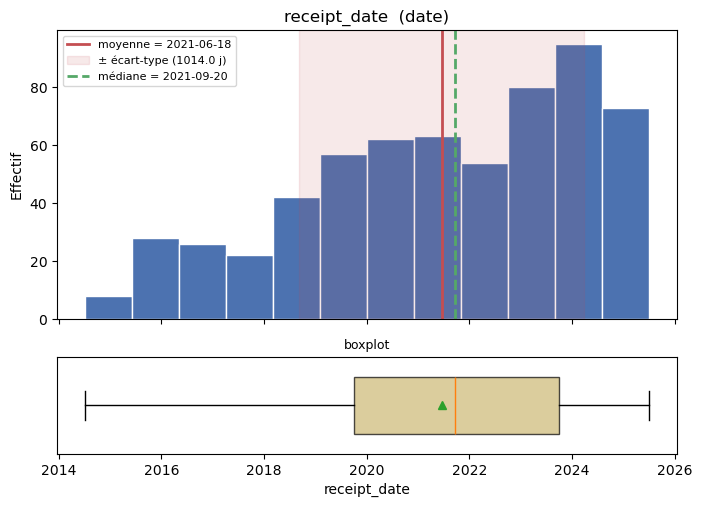


=== receiving_facility_code  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 30)
  Mode : FCL-1011 (21.8 %)
                         effectif     %
receiving_facility_code                
FCL-1011                      133  21.8
FCL-1007                       76  12.5
FCL-1010                       61  10.0
FCL-1019                       54   8.9
FCL-1030                       37   6.1
FCL-1020                       33   5.4
FCL-1016                       23   3.8
FCL-1015                       23   3.8
FCL-1029                       20   3.3
FCL-1025                       18   3.0
FCL-1014                       15   2.5
FCL-1009                       12   2.0


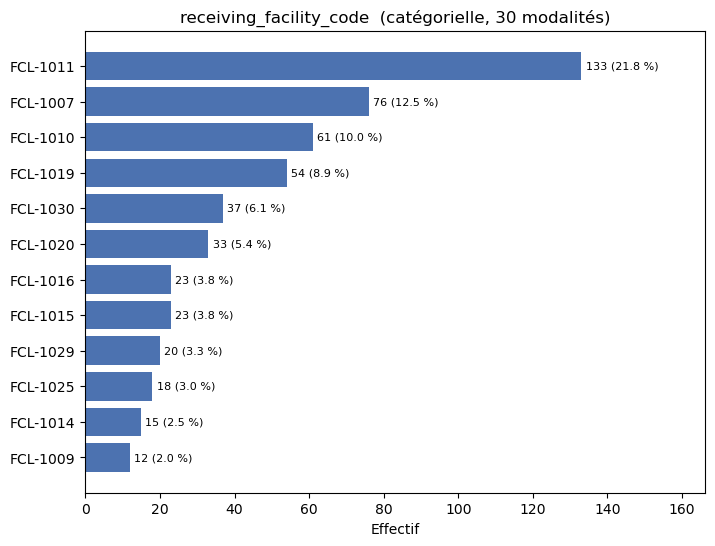


=== supplier_partner_code  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 69)
  Mode : BP-30078 (17.9 %)
                       effectif     %
supplier_partner_code                
BP-30078                    109  17.9
BP-30056                     25   4.1
BP-30080                     14   2.3
BP-30009                     13   2.1
BP-30059                     13   2.1
BP-30028                     12   2.0
BP-30001                     12   2.0
BP-30021                     11   1.8
BP-30057                     11   1.8
BP-30033                     11   1.8
BP-30066                     10   1.6
BP-30030                     10   1.6


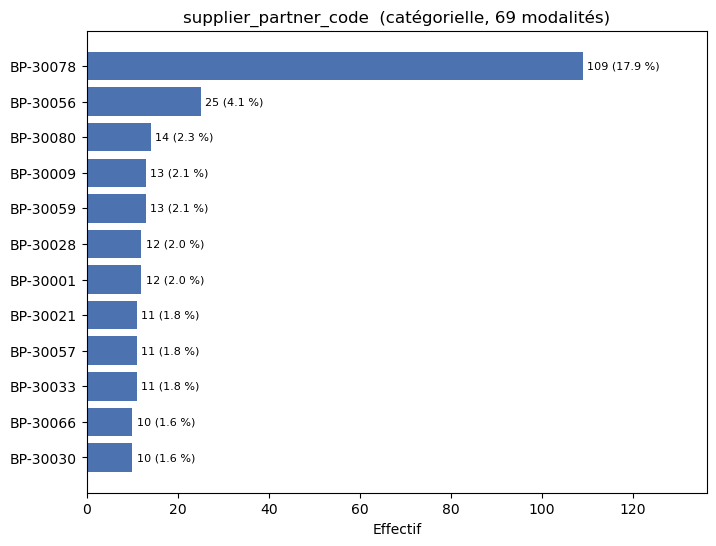


=== received_quantity  [continue] ===
  Effectif : 610  (manquants : 0, valeurs distinctes : 141)
  Moyenne ± écart-type : 20.592 ± 22.947
  Médiane [min ; Q1 - Q3 ; max] : 13.000 [0.780 ; 1.000 - 29.000 ; 90.000]
  Asymétrie : 1.33


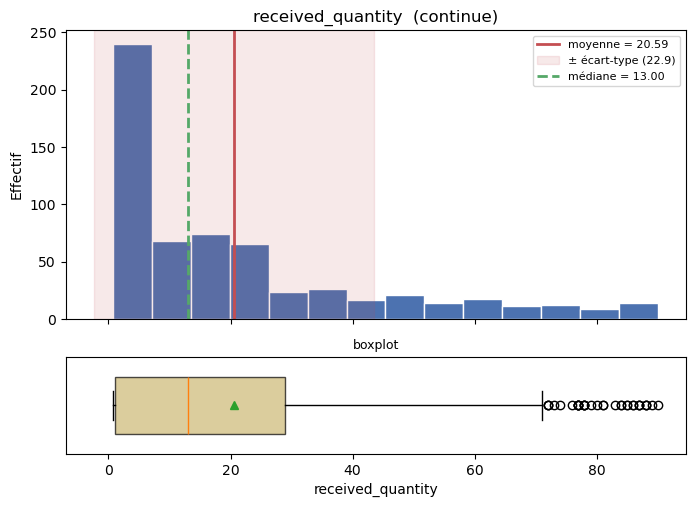


=== received_unit  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 9)
  Mode : case (25.6 %)
               effectif     %
received_unit                
case                156  25.6
service             121  19.8
unit                120  19.7
kit                  56   9.2
pallet               46   7.5
pack                 41   6.7
sealed_lot           39   6.4
contract             21   3.4
grant                10   1.6


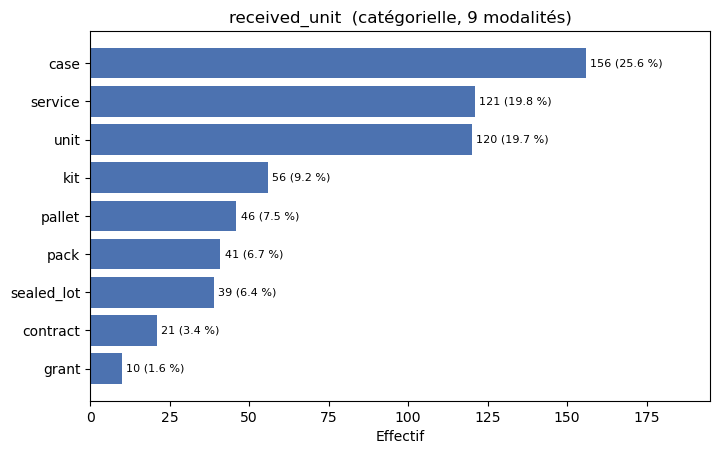


=== inspection_status  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 4)
  Mode : accepted (82.8 %)
                   effectif     %
inspection_status                
accepted                505  82.8
conditional              67  11.0
held                     34   5.6
non_renseigne             4   0.7


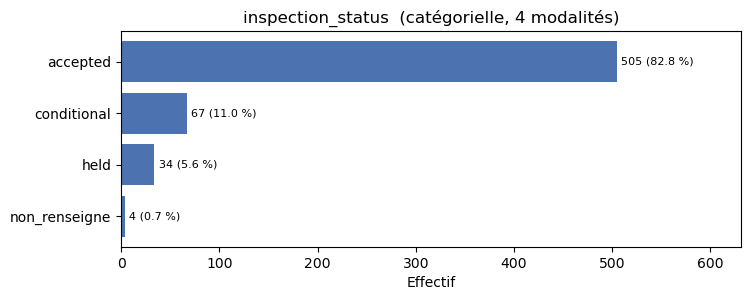


=== receipt_status  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 2)
  Mode : posted (94.4 %)
                effectif     %
receipt_status                
posted               576  94.4
quality_hold          34   5.6


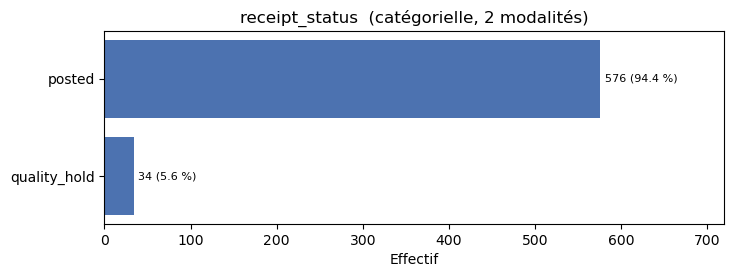


=== storage_location_code  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 42)
  Mode : BIN-07 (4.1 %)
                       effectif    %
storage_location_code               
BIN-07                       25  4.1
BIN-41                       21  3.4
BIN-34                       21  3.4
BIN-40                       20  3.3
BIN-16                       20  3.3
BIN-35                       19  3.1
BIN-18                       19  3.1
BIN-29                       19  3.1
BIN-12                       18  3.0
BIN-32                       18  3.0
BIN-14                       17  2.8
BIN-38                       17  2.8


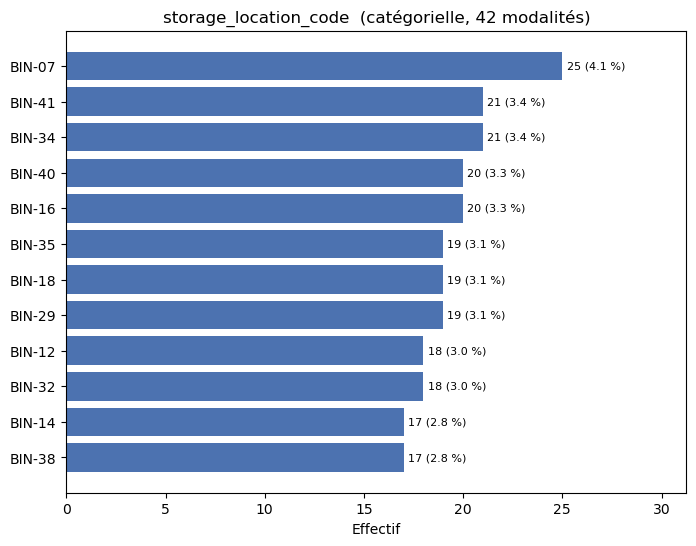


=== item_category  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 18)
  Mode : medical_consumables (12.1 %)
                        effectif     %
item_category                         
medical_consumables           74  12.1
monitoring_equipment          56   9.2
cold_storage_equipment        51   8.4
protective_equipment          47   7.7
agricultural_product          46   7.5
laboratory_material           41   6.7
biological_sample             39   6.4
office_supply                 35   5.7
transport_service             30   4.9
other                         28   4.6
refrigeration_service         27   4.4
consulting_service            25   4.1


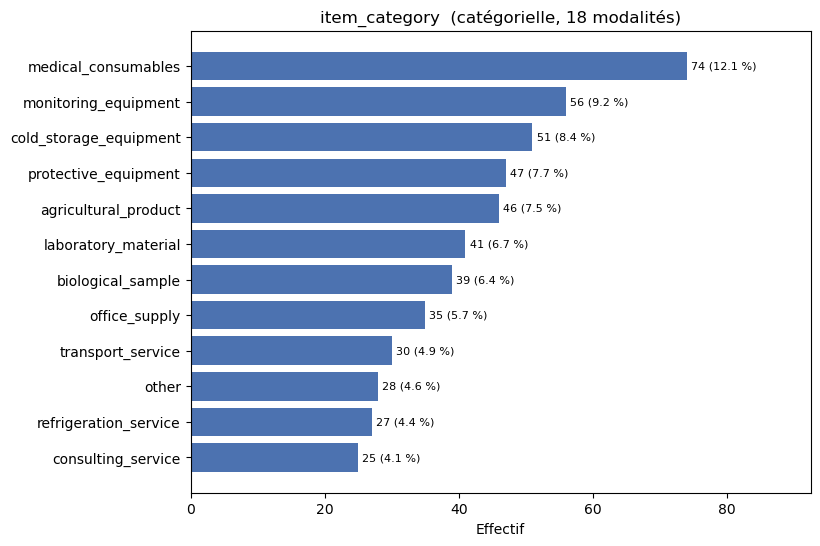


=== authorization_class  [catégorielle] ===
  Effectif : 610  (manquants : 0, modalités : 4)
  Mode : ordinary (61.8 %)
                     effectif     %
authorization_class                
ordinary                  377  61.8
expedited                 118  19.3
restricted                 78  12.8
emergency                  37   6.1


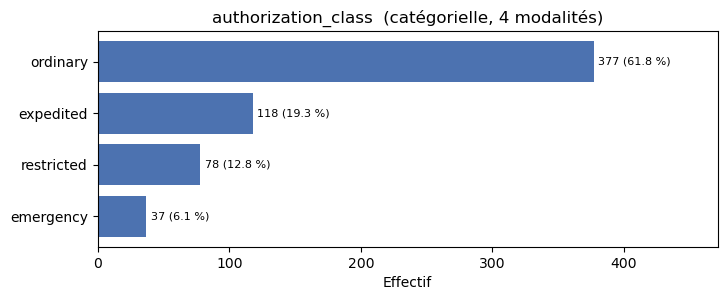


=== taux_reception  [continue] ===
  Effectif : 610  (manquants : 0, valeurs distinctes : 59)
  Moyenne ± écart-type : 0.986 ± 0.043
  Médiane [min ; Q1 - Q3 ; max] : 1.000 [0.780 ; 1.000 - 1.000 ; 1.000]
  Asymétrie : -3.29


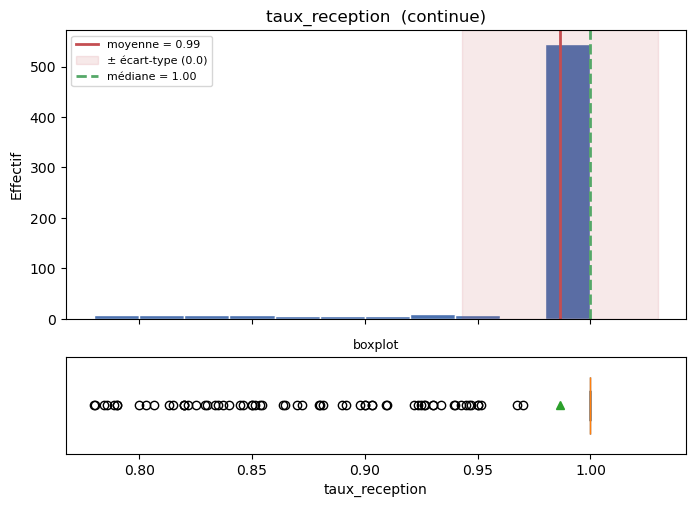


=== retard_jours  [discrète] ===
  Effectif : 610  (manquants : 0, valeurs distinctes : 12)
  Moyenne ± écart-type : 1.974 ± 3.288
  Médiane [min ; Q1 - Q3 ; max] : 2.000 [-22.000 ; -1.000 - 5.000 ; 7.000]
  Asymétrie : -0.58


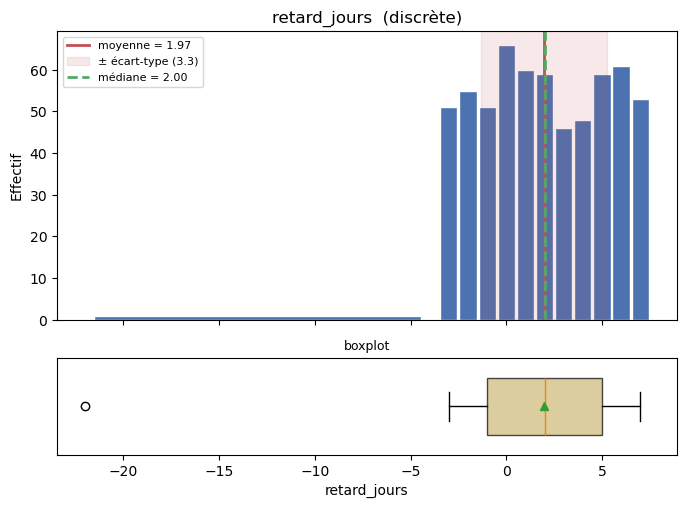


=== delai_commande_jours  [continue] ===
  Effectif : 610  (manquants : 0, valeurs distinctes : 45)
  Moyenne ± écart-type : 25.952 ± 10.549
  Médiane [min ; Q1 - Q3 ; max] : 26.000 [4.000 ; 17.000 - 35.000 ; 48.000]
  Asymétrie : 0.06


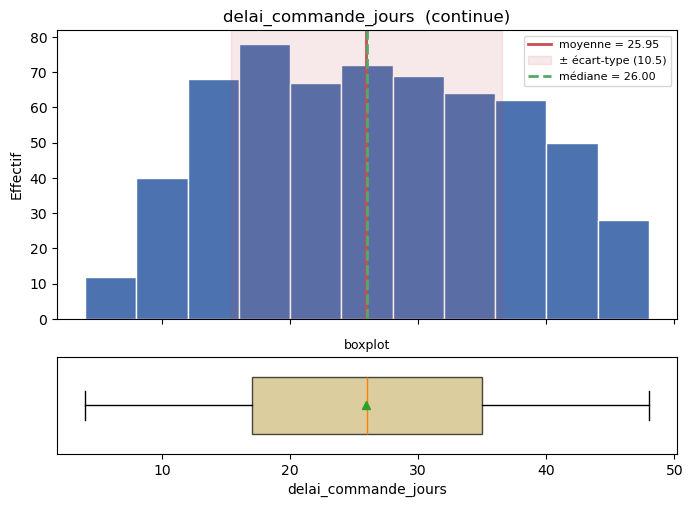

In [18]:
colonnes_univariees = ["receipt_date", "receiving_facility_code", "supplier_partner_code",
                       "received_quantity", "received_unit", "inspection_status", "receipt_status",
                       "storage_location_code", "item_category", "authorization_class",
                       "taux_reception", "retard_jours", "delai_commande_jours"]
resume = analyser_variables(gr, columns=colonnes_univariees, max_modalites_affichees=12)

Les réceptions vont de juillet 2014 à juin 2025. Il y en a 23 en 2015, puis le nombre monte jusqu'à 97 en 2023, redescend à 60 en 2024, et on en a déjà 61 sur le premier semestre 2025.

30 sites reçoivent de la marchandise, mais le siège de Meridian (`FCL-1011`) en reçoit à lui seul 21,8 %, suivi de deux sites cliniques d'Asterion, `FCL-1007` (12,5 %) et `FCL-1010` (10,0 %). Côté fournisseurs, c'est Meridian elle-même qui arrive en tête avec 17,9 % des réceptions (109), alors que le deuxième n'est qu'à 4,1 %. Une entreprise enregistrée comme transporteur qui se livre elle-même, on trouve ça étrange.

La quantité a une moyenne de 20,6 et une médiane de 13 (de 0,78 à 90), mais comme ça mélange des caisses et des services, la moyenne globale n'a pas vraiment de sens. Pour les unités, on a surtout des caisses (25,6 %), des services (19,8 %) et des unités (19,7 %). L'inspection donne `accepted` dans 82,8 % des cas, `conditional` 11,0 %, `held` 5,6 % et vide 0,7 %. Il y a 18 catégories d'articles, les consommables médicaux en premier (12 %), et 39 réceptions d'échantillons biologiques. Pour l'autorisation : `ordinary` 61,8 %, `expedited` 19,3 %, `restricted` 12,8 %, `emergency` 6,1 %.

Pour les colonnes qu'on a ajoutées, le taux de réception vaut presque toujours 1 avec quelques réceptions incomplètes (minimum 0,78). Le délai entre commande et réception est de 26 jours en moyenne (de 4 à 48). Le retard va de −3 à +7 jours de façon presque uniforme, sauf une réception livrée 22 jours en avance (`RCV-2025-00610`, la dernière ligne du fichier). Vu à quel point le reste est régulier, cette valeur est une bonne candidate pour la partie anomalies.

### 3.2 La quantité, unité par unité

Comme la quantité ne veut pas dire la même chose selon l'unité, on fait un histogramme par unité.

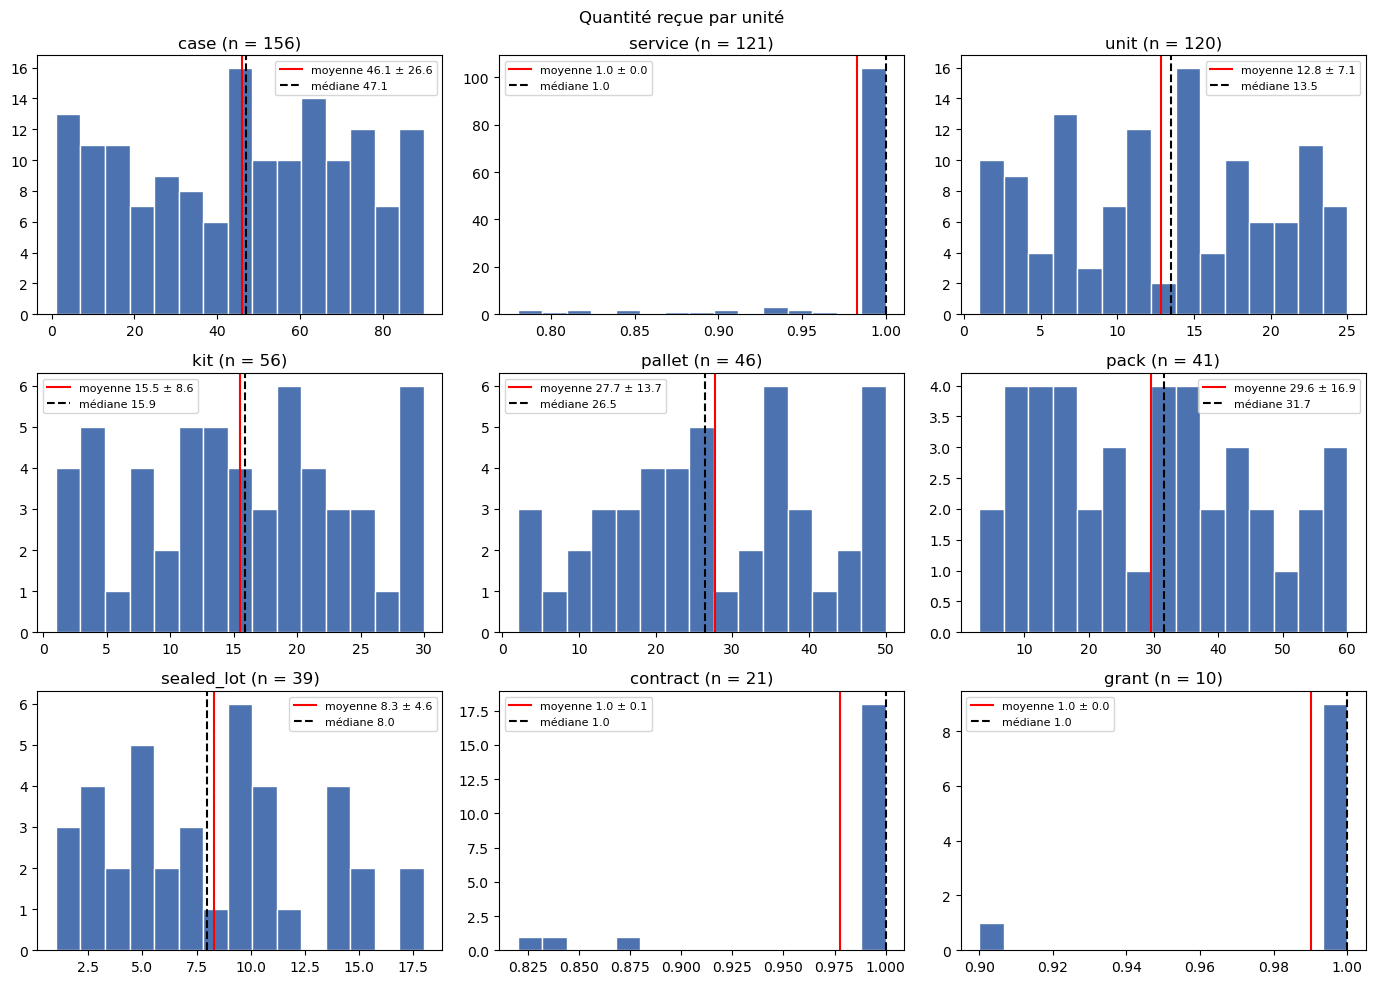

In [19]:
unites = gr.received_unit.value_counts().index
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, u in zip(axes.ravel(), unites):
    s = gr.loc[gr.received_unit == u, "received_quantity"]
    ax.hist(s, bins=15, color="#4C72B0", edgecolor="white")
    ax.axvline(s.mean(), color="red", label=f"moyenne {s.mean():.1f} ± {s.std():.1f}")
    ax.axvline(s.median(), color="black", ls="--", label=f"médiane {s.median():.1f}")
    ax.set_title(f"{u} (n = {len(s)})")
    ax.legend(fontsize=8)
fig.suptitle("Quantité reçue par unité")
plt.tight_layout()
plt.show()

receipt_date
2014     1
2015    23
2016    24
2017    29
2018    47
2019    59
2020    68
2021    60
2022    81
2023    97
2024    60
2025    61


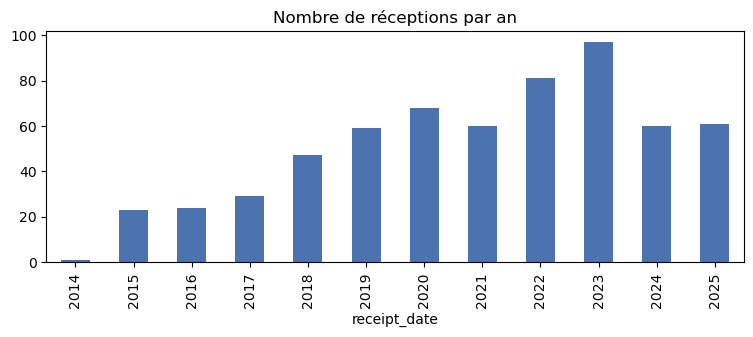

In [20]:
# Activité dans le temps : nombre de réceptions par an
par_an = gr.groupby(gr.receipt_date.dt.year).size()
print(par_an.to_string())
par_an.plot(kind="bar", figsize=(9, 3), title="Nombre de réceptions par an", color="#4C72B0")
plt.show()

Chaque unité a sa propre échelle : jusqu'à 90 caisses, 60 paquets, 50 palettes, 30 kits, 25 unités, 18 lots, et presque toujours 1 pour les services, contrats et subventions. Chaque catégorie d'article n'utilise qu'une seule unité (par exemple échantillon biologique → lot scellé).

Les histogrammes sont plats, comme si les quantités étaient tirées au hasard entre deux bornes. On pense que les données sont synthétiques, donc on ne va pas trop interpréter la forme des distributions. Pour comparer des quantités il faut rester à unité égale, ou utiliser le taux de réception qui n'a pas d'unité.

Sur les années, l'activité passe de 23-29 réceptions par an (2015-2017) à 97 en 2023, baisse en 2024 puis repart en 2025.

---
## 4. Corrélations

On calcule Spearman et Pearson et on regarde aussi les nuages de points pour voir la forme du lien. Pour les catégories on prend le V de Cramér (0 = pas de lien, 1 = lien parfait). Bien sûr, une corrélation ne veut pas dire qu'il y a une cause.

### 4.1 Spearman et Pearson

Variables utilisées (6) : ['receipt_date (date -> jours)', 'received_quantity (numérique)', 'ordered_quantity (numérique)', 'taux_reception (numérique)', 'retard_jours (numérique)', 'delai_commande_jours (numérique)']


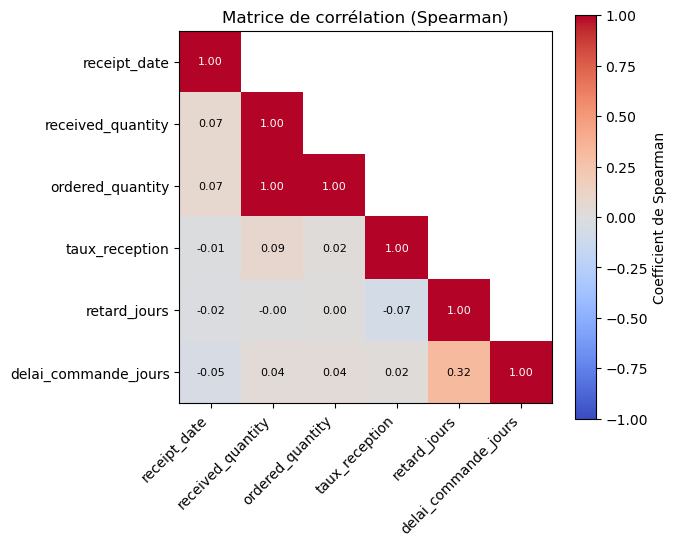


Paires avec |spearman| >= 0.5 :
      variable_1        variable_2   valeur
ordered_quantity received_quantity 0.996213


In [21]:
numeriques = ["receipt_date", "received_quantity", "ordered_quantity", "taux_reception",
              "retard_jours", "delai_commande_jours"]
spearman = matrice_correlation(gr, columns=numeriques, method="spearman", seuil_paires=0.5)

Variables utilisées (6) : ['receipt_date (date -> jours)', 'received_quantity (numérique)', 'ordered_quantity (numérique)', 'taux_reception (numérique)', 'retard_jours (numérique)', 'delai_commande_jours (numérique)']


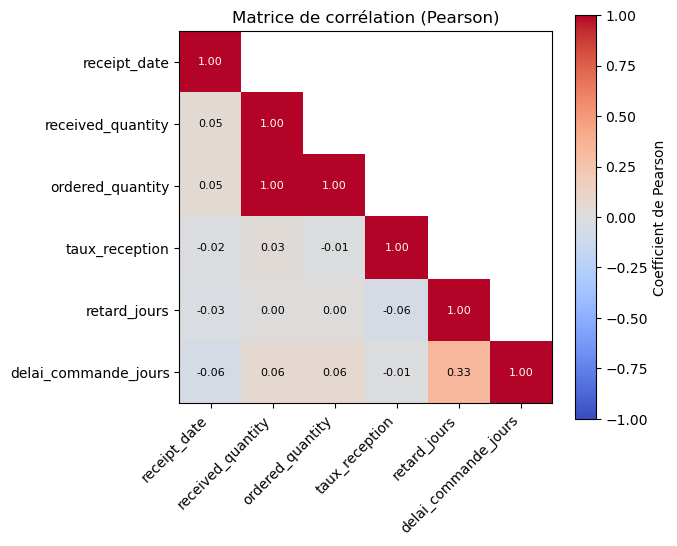


Paires avec |pearson| >= 0.5 :
      variable_1        variable_2   valeur
ordered_quantity received_quantity 0.997809


In [22]:
pearson = matrice_correlation(gr, columns=numeriques, method="pearson", seuil_paires=0.5)

In [23]:
ecart = (spearman - pearson).abs()
print("Paires où Spearman et Pearson diffèrent de plus de 0,15 :")
paires = [(a, b, spearman.loc[a, b], pearson.loc[a, b]) for i, a in enumerate(ecart.index)
          for b in ecart.columns[i + 1:] if ecart.loc[a, b] > 0.15]
for a, b, s, p in paires:
    print(f"  {a} - {b} : Spearman {s:.2f} | Pearson {p:.2f}")

Paires où Spearman et Pearson diffèrent de plus de 0,15 :


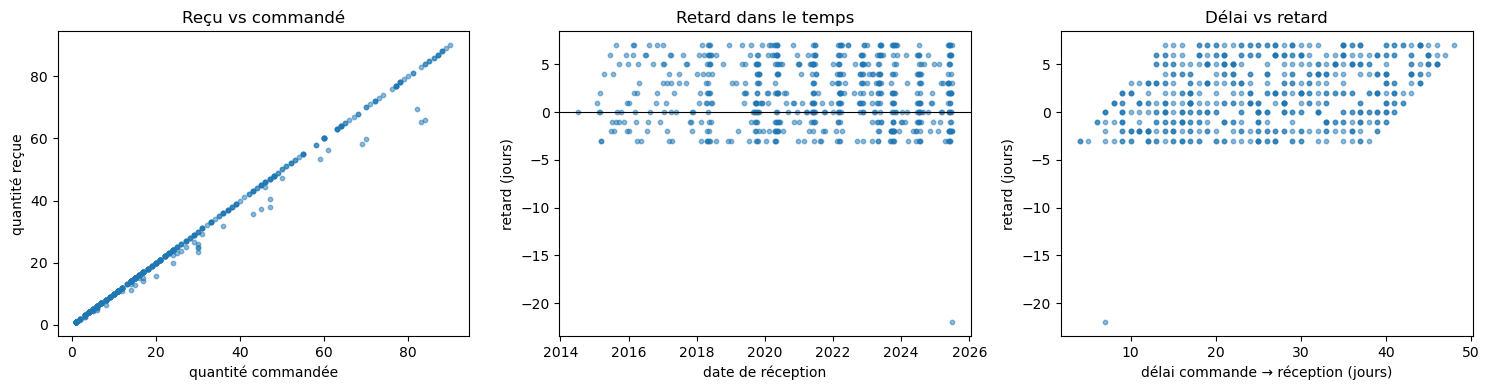

In [24]:
# Visualisation des relations
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(gr.ordered_quantity, gr.received_quantity, s=10, alpha=.5)
axes[0].set(xlabel="quantité commandée", ylabel="quantité reçue", title="Reçu vs commandé")
axes[1].scatter(gr.receipt_date, gr.retard_jours, s=10, alpha=.5)
axes[1].axhline(0, color="black", lw=.8)
axes[1].set(xlabel="date de réception", ylabel="retard (jours)", title="Retard dans le temps")
axes[2].scatter(gr.delai_commande_jours, gr.retard_jours, s=10, alpha=.5)
axes[2].set(xlabel="délai commande → réception (jours)", ylabel="retard (jours)", title="Délai vs retard")
plt.tight_layout()
plt.show()

On trouve une seule corrélation forte, entre quantité reçue et quantité commandée (0,996 et 0,998), ce qui est normal. Tout le reste est faible : la date, le retard, le délai et le taux de réception ne sont pas liés entre eux. Spearman et Pearson donnent toujours à peu près la même chose, donc il n'y a pas de lien non linéaire caché. Le retard ne change pas avec le temps, à part le point à −22 jours.

Donc aucune variable numérique n'explique le manque de marchandise. Si ça a une cause, il faudra la chercher du côté du site, du fournisseur ou de la catégorie.

### 4.2 Liens entre catégories

Variables catégorielles utilisées (6) : ['receiving_facility_code', 'received_unit', 'inspection_status', 'receipt_status', 'item_category', 'authorization_class']


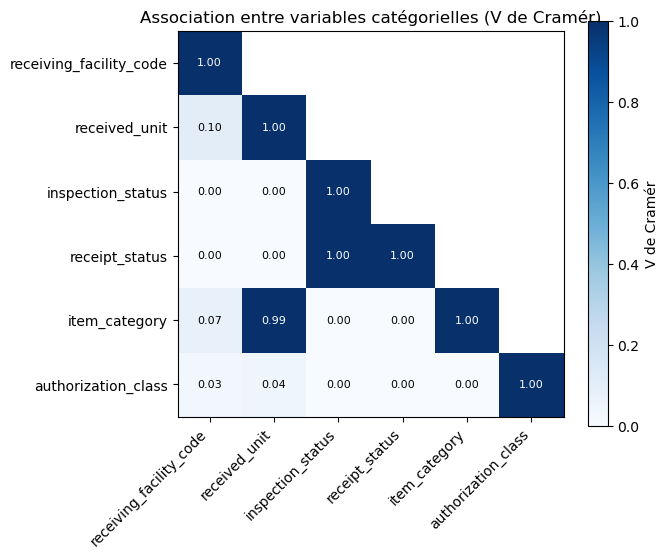


Paires avec |V de Cramér| >= 0.5 :
    variable_1        variable_2   valeur
receipt_status inspection_status 0.998354
 item_category     received_unit 0.992484


In [25]:
nominales = ["receiving_facility_code", "received_unit", "inspection_status", "receipt_status",
             "item_category", "authorization_class"]
cramer = matrice_cramer(gr, columns=nominales)

In [26]:
print(pd.crosstab(gr.item_category, gr.inspection_status, margins=True).to_string())
print()
print(pd.crosstab(gr.authorization_class, gr.inspection_status, margins=True).to_string())

inspection_status       accepted  conditional  held  non_renseigne  All
item_category                                                          
agricultural_equipment        20            2     1              0   23
agricultural_product          32           11     2              1   46
biological_sample             31            6     2              0   39
cold_storage_equipment        40            6     5              0   51
communication_service         13            2     2              0   17
consulting_service            23            1     1              0   25
grant                          9            1     0              0   10
laboratory_material           35            4     1              1   41
legal_service                 18            3     1              0   22
medical_consumables           60            8     5              1   74
medical_equipment             17            1     0              0   18
monitoring_equipment          47            7     2             

Inspection et statut sont redondants (V = 1), catégorie et unité aussi (V = 0,99). On garde une seule colonne de chaque paire.

---
## 5. Regrouper les réceptions

Avant de lancer un algorithme de clustering, il faut choisir les variables, la distance et le nombre de dimensions. Ensuite on réduit les dimensions (PCA, t-SNE) et on teste trois méthodes de clustering (hiérarchique, K-means, DBSCAN).

### 5.1 On ajoute le contexte du site et du fournisseur

Les premières analyses montrent que c'est le contexte qui compte. On ajoute donc deux variables : est-ce que le site fait partie du « groupe des 10 » (les sites dont les coordonnées n'ont que 2 décimales, voir `erp_facilities`), et est-ce que le fournisseur a un numéro de la série 01 (entité du registre public, voir `erp_business_partners`).

In [27]:
fa = pd.read_csv(DATA / "erp_facilities.csv", dtype=str).apply(lambda s: s.str.strip())
fa["site_groupe_10"] = (fa.latitude.str.split(".").str[1].str.len().combine(
    fa.longitude.str.split(".").str[1].str.len(), max) <= 2).astype(int)
bp = pd.read_csv(DATA / "erp_business_partners.csv", dtype=str).apply(lambda s: s.str.strip())
bp["partner_role"] = bp.partner_role.str.lower()
bp["reg_serie"] = bp.external_registration_number.str.extract(r"-(\d{2})\d{3}$")[0].fillna("aucun")
po_desc = pd.read_csv(DATA / "purchase_order_lines.csv", dtype=str).drop_duplicates()[
    ["purchase_order_number", "item_description", "unit_price"]]
po_desc["item_description"] = po_desc.item_description.str.strip()

gr = (gr.merge(fa[["facility_code", "site_groupe_10", "region", "latitude", "longitude", "facility_category"]]
               .rename(columns={"facility_code": "receiving_facility_code", "region": "site_region",
                                "facility_category": "site_categorie"}), on="receiving_facility_code", how="left")
        .merge(bp[["partner_code", "partner_role", "reg_serie", "risk_class"]]
               .rename(columns={"partner_code": "supplier_partner_code", "partner_role": "fournisseur_role",
                                "reg_serie": "fournisseur_serie", "risk_class": "fournisseur_risque"}), on="supplier_partner_code", how="left")
        .merge(po_desc, on="purchase_order_number", how="left"))
gr["latitude"] = gr.latitude.astype(float)
gr["longitude"] = gr.longitude.astype(float)
gr["incomplete"] = (gr.taux_reception.round(4) < 1).astype(int)
print("Lignes :", len(gr), "| valeurs manquantes après jointures :", int(gr.isna().sum().sum()))
print("Réceptions sur les 10 sites du groupe :", int(gr.site_groupe_10.sum()),
      "| fournies par une entité de la série 01 :", int((gr.fournisseur_serie == "01").sum()))

Lignes : 610 | valeurs manquantes après jointures : 0
Réceptions sur les 10 sites du groupe : 465 | fournies par une entité de la série 01 : 296


### 5.2 Variables, distance et échelles

| Variable | Gardée ? | Traitement | Pourquoi |
|---|---|---|---|
| taux de réception | oui | centrée-réduite | c'est le cœur de l'analyse |
| retard, délai | oui | centrées-réduites | en jours, sinon elles écraseraient le taux |
| quantité | oui, en rang dans son unité (0 à 1) | rang par unité | on ne compare pas caisses et services, mais on peut comparer des rangs |
| inspection | oui | une colonne 0/1 par valeur | catégorie sans ordre |
| statut de réception | non | | redondant avec l'inspection |
| unité | non | | redondante avec la catégorie |
| autorisation | oui | une colonne 0/1 par valeur | |
| groupe des 10, série 01 | oui | 0/1 | contexte |
| codes site, fournisseur, catégorie | non | | plus de 100 colonnes presque vides |

On prend la distance euclidienne. On centre-réduit au lieu de ramener entre 0 et 1, parce qu'avec un min-max le retard de −22 jours écraserait toutes les autres valeurs. Les colonnes 0/1 restent comme elles sont.

In [28]:
from sklearn.preprocessing import StandardScaler

gr["quantite_rang_unite"] = gr.groupby("received_unit").received_quantity.rank(pct=True)
num = ["taux_reception", "retard_jours", "delai_commande_jours"]
X = pd.concat([
    pd.DataFrame(StandardScaler().fit_transform(gr[num]), columns=[c + "_z" for c in num]),
    gr[["quantite_rang_unite", "site_groupe_10"]],
    (gr.fournisseur_serie == "01").astype(int).rename("fournisseur_serie01"),
    pd.get_dummies(gr.inspection_status, prefix="insp").astype(int),
    pd.get_dummies(gr.authorization_class, prefix="auth").astype(int),
], axis=1)
print("Matrice de travail :", X.shape)
print("Corrélations fortes (|r| > 0.7) entre variables gardées :")
c = X.corr().abs().where(lambda m: np.triu(np.ones(m.shape, bool), 1))
print(c.stack()[lambda s: s > 0.7].round(2).to_string() or "  aucune")

Matrice de travail : (610, 14)
Corrélations fortes (|r| > 0.7) entre variables gardées :
insp_accepted  insp_conditional    0.77


On obtient 610 réceptions × 14 colonnes. Pas de colonne redondante.

### 5.3 PCA et t-SNE

La PCA cherche les axes qui gardent le plus de variance. Elle est linéaire et on peut interpréter ses axes. Le t-SNE, lui, garde surtout les voisinages et peut faire apparaître des groupes que la PCA écrase, mais ses axes n'ont pas de sens. On utilise donc la PCA pour comprendre et le t-SNE pour visualiser.

Variance expliquée par axe : [0.307 0.23  0.153 0.077 0.061 0.049] | cumul 2 axes : 0.537
                         PC1   PC2
taux_reception_z       -0.15  0.98
retard_jours_z          0.70  0.03
delai_commande_jours_z  0.69  0.18
quantite_rang_unite    -0.00  0.07
auth_expedited          0.01 -0.04
fournisseur_serie01    -0.03  0.02
insp_accepted           0.02 -0.03
site_groupe_10         -0.02 -0.00


c:\Users\Tech For All\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Le fichier spécifié est introuvable
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Tech For All\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Tech For All\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Tech For All\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~

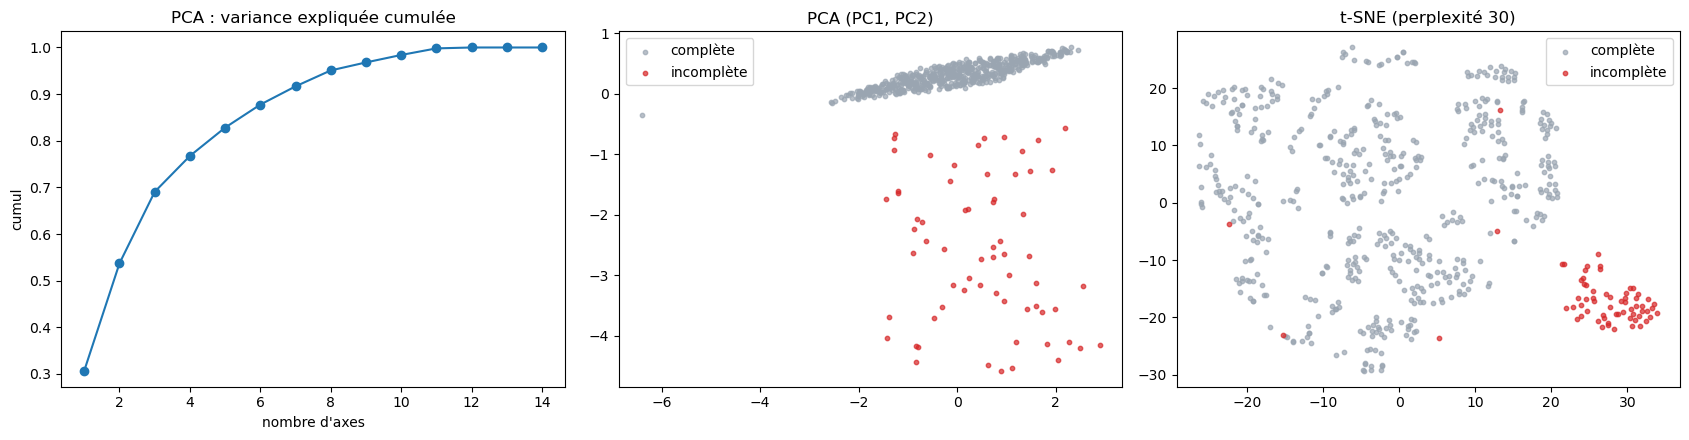

In [29]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pca = PCA().fit(X)
var = pca.explained_variance_ratio_
print("Variance expliquée par axe :", np.round(var[:6], 3), "| cumul 2 axes :", round(var[:2].sum(), 3))
contrib = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"]).round(2)
print(contrib.reindex(contrib.abs().max(axis=1).sort_values(ascending=False).index).head(8).to_string())

P = pca.transform(X)[:, :2]
T = TSNE(n_components=2, perplexity=30, random_state=0, init="pca").fit_transform(X)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(range(1, len(var) + 1), var.cumsum(), marker="o")
axes[0].set(title="PCA : variance expliquée cumulée", xlabel="nombre d'axes", ylabel="cumul")
for ax, Y, titre in [(axes[1], P, "PCA (PC1, PC2)"), (axes[2], T, "t-SNE (perplexité 30)")]:
    for val, coul, lab in [(0, "#9aa5b1", "complète"), (1, "#d62728", "incomplète")]:
        m = gr.incomplete == val
        ax.scatter(Y[m, 0], Y[m, 1], s=10, c=coul, label=lab, alpha=.7)
    ax.set_title(titre); ax.legend()
plt.tight_layout(); plt.show()

Avec la PCA, les deux premiers axes n'expliquent que 53,7 % de la variance et il en faut 6 pour dépasser 85 %, donc il n'y a pas de structure simple. Le premier axe correspond au temps de livraison (retard et délai) et le deuxième au taux de réception. Sur ce plan, les réceptions incomplètes forment un nuage à part qui s'étale sur tout le premier axe, ce qui montre qu'être incomplète n'a rien à voir avec le retard. Le point isolé à gauche, c'est la livraison 22 jours en avance.

Le t-SNE montre une dizaine d'îlots qui correspondent surtout aux combinaisons inspection × autorisation (il sépare beaucoup les colonnes 0/1). Les réceptions incomplètes tombent presque toutes dans le même îlot. Les deux méthodes vont dans le même sens : la seule vraie structure, c'est le fait d'être incomplète ou non.

### 5.4 Regroupement

On a testé trois méthodes. Le clustering hiérarchique avec Ward ne demande pas de fixer le nombre de groupes, le dendrogramme aide à choisir où couper, et Ward va bien avec la distance euclidienne ; il est lent sur de gros volumes mais 610 lignes ça passe. K-means est rapide mais il faut choisir k, alors on teste k de 2 à 8 et on garde le meilleur score de silhouette. Enfin DBSCAN ne demande pas de k, accepte des groupes de forme quelconque et surtout laisse de côté les points qui ne ressemblent à rien (le bruit).

c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to 

Silhouette K-means : {2: np.float64(0.202), 3: np.float64(0.237), 4: np.float64(0.198), 5: np.float64(0.197), 6: np.float64(0.19), 7: np.float64(0.193), 8: np.float64(0.174)} -> k = 3
DBSCAN : eps = 1.71 (95e centile de la distance au 5e voisin) -> 1 groupes, 15 points de bruit
Accord Ward / K-means (indice de Rand ajusté) : 0.45


c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(


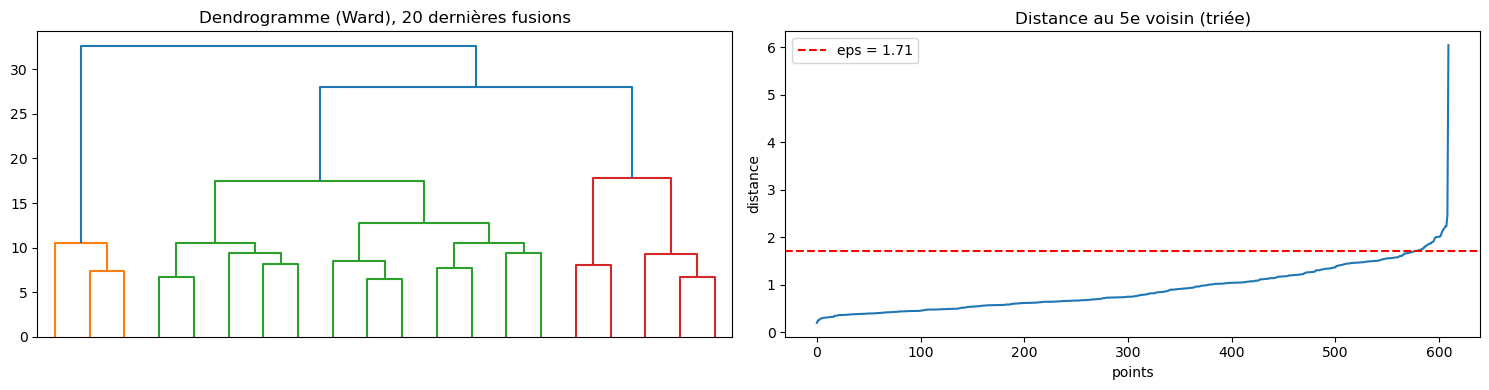

In [30]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.neighbors import NearestNeighbors

Z = linkage(X, method="ward")
sil = {k: silhouette_score(X, KMeans(k, n_init=10, random_state=0).fit_predict(X)) for k in range(2, 9)}
k_best = max(sil, key=sil.get)
print("Silhouette K-means :", {k: round(v, 3) for k, v in sil.items()}, "-> k =", k_best)

gr["cl_ward"] = fcluster(Z, k_best, criterion="maxclust")
gr["cl_kmeans"] = KMeans(k_best, n_init=10, random_state=0).fit_predict(X)
dist_k = np.sort(NearestNeighbors(n_neighbors=5).fit(X).kneighbors(X)[0][:, -1])
eps = float(np.quantile(dist_k, 0.95))
gr["cl_dbscan"] = DBSCAN(eps=eps, min_samples=5).fit_predict(X)
print(f"DBSCAN : eps = {eps:.2f} (95e centile de la distance au 5e voisin) -> "
      f"{gr.cl_dbscan.max() + 1} groupes, {int((gr.cl_dbscan == -1).sum())} points de bruit")
print("Accord Ward / K-means (indice de Rand ajusté) :", round(adjusted_rand_score(gr.cl_ward, gr.cl_kmeans), 2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dendrogram(Z, truncate_mode="lastp", p=20, ax=axes[0], no_labels=True)
axes[0].set_title("Dendrogramme (Ward), 20 dernières fusions")
axes[1].plot(dist_k); axes[1].axhline(eps, color="red", ls="--", label=f"eps = {eps:.2f}")
axes[1].set(title="Distance au 5e voisin (triée)", xlabel="points", ylabel="distance"); axes[1].legend()
plt.tight_layout(); plt.show()

In [31]:
profil = gr.groupby("cl_kmeans").agg(
    n=("receipt_number", "size"), incompletes=("incomplete", "mean"), taux_moyen=("taux_reception", "mean"),
    retard_moyen=("retard_jours", "mean"), site_groupe_10=("site_groupe_10", "mean"),
    serie01=("fournisseur_serie", lambda s: (s == "01").mean()),
    inspection_dominante=("inspection_status", lambda s: s.value_counts().index[0]),
    autorisation_dominante=("authorization_class", lambda s: s.value_counts().index[0])).round(2)
print(profil.to_string())
print("\nRéceptions incomplètes par groupe DBSCAN (-1 = bruit) :")
print(pd.crosstab(gr.cl_dbscan, gr.incomplete, margins=True).to_string())

             n  incompletes  taux_moyen  retard_moyen  site_groupe_10  serie01 inspection_dominante autorisation_dominante
cl_kmeans                                                                                                                 
0          280         0.03        1.00         -0.55            0.80     0.53             accepted               ordinary
1           46         1.00        0.84          2.37            0.74     0.46             accepted               ordinary
2          284         0.04        1.00          4.40            0.73     0.44             accepted               ordinary

Réceptions incomplètes par groupe DBSCAN (-1 = bruit) :
incomplete    0   1  All
cl_dbscan               
-1            2  13   15
0           543  52  595
All         545  65  610


K-means trouve 3 groupes (silhouette 0,24, assez faible) : complètes à l'heure, complètes en retard, et incomplètes. DBSCAN met 15 points à part, dont 13 réceptions incomplètes. Le manque est donc la seule vraie structure.

| Groupe K-means | Taille | Incomplètes | Retard moyen | En clair |
|---|---|---|---|---|
| 0 | 280 | 3 % | −0,6 j | complètes, à l'heure ou en avance |
| 1 | 46 | 100 % | +2,4 j | incomplètes (taux moyen 0,84) |
| 2 | 284 | 4 % | +4,4 j | complètes, en retard |

---
## 6. Règles et anomalies

### 6.1 Quels sites reçoivent quels articles ?

On compte les réceptions par site et par catégorie, puis on met en pourcentage par ligne pour pouvoir comparer des sites de tailles différentes.

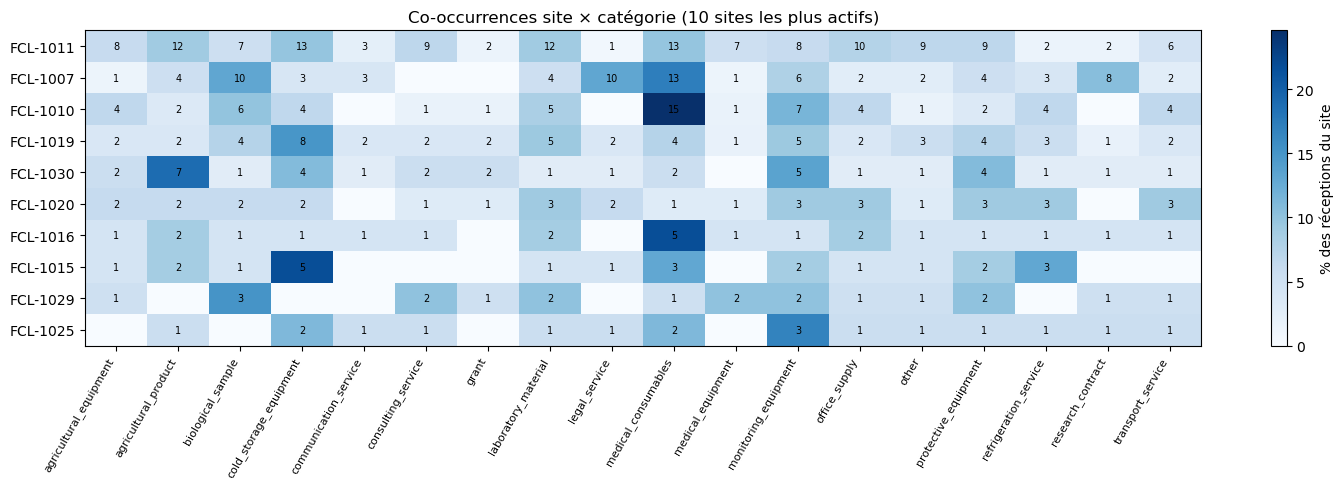

Échantillons biologiques reçus par site : {'FCL-1007': 10, 'FCL-1011': 7, 'FCL-1010': 6, 'FCL-1019': 4, 'FCL-1029': 3, 'FCL-1020': 2, 'FCL-1022': 1, 'FCL-1030': 1, 'FCL-1009': 1, 'FCL-1016': 1, 'FCL-1015': 1, 'FCL-1005': 1, 'FCL-1006': 1}


In [32]:
top_sites = gr.receiving_facility_code.value_counts().index[:10]
co = pd.crosstab(gr.receiving_facility_code, gr.item_category).loc[top_sites]
co_pct = co.div(co.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(15, 5))
im = ax.imshow(co_pct, cmap="Blues", aspect="auto")
ax.set_xticks(range(co_pct.shape[1])); ax.set_xticklabels(co_pct.columns, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(top_sites))); ax.set_yticklabels(top_sites)
for i in range(co_pct.shape[0]):
    for j in range(co_pct.shape[1]):
        if co.iloc[i, j]:
            ax.text(j, i, int(co.iloc[i, j]), ha="center", va="center", fontsize=7)
plt.colorbar(im, label="% des réceptions du site"); ax.set_title("Co-occurrences site × catégorie (10 sites les plus actifs)")
plt.tight_layout(); plt.show()
print("Échantillons biologiques reçus par site :",
      gr[gr.item_category == "biological_sample"].receiving_facility_code.value_counts().to_dict())

Chaque site a sa spécialité, sauf le siège de Meridian qui reçoit de tout (18 catégories). Les échantillons biologiques vont surtout vers des sites du groupe des 10.

### 6.2 Règles d'association (Apriori)

In [33]:
from utils.pattern_detection import itemsets_frequents, regles_association

items = pd.DataFrame({
    "reception": np.where(gr.incomplete == 1, "incomplete", "complete"),
    "site_groupe": np.where(gr.site_groupe_10 == 1, "groupe_10", "autres"),
    "site": gr.receiving_facility_code,
    "fournisseur": np.where(gr.supplier_partner_code == "BP-30078", "meridian", "autre"),
    "fournisseur_serie": gr.fournisseur_serie,
    "fournisseur_role": gr.fournisseur_role,
    "categorie": gr.item_category,
    "inspection": gr.inspection_status,
    "autorisation": gr.authorization_class,
    "retard": pd.cut(gr.retard_jours, [-100, -1, 3, 100], labels=["avance", "0_3j", "plus_3j"]).astype(str),
    "periode": pd.cut(gr.receipt_date.dt.year, [2013, 2018, 2022, 2025], labels=["2014_18", "2019_22", "2023_25"]).astype(str),
})
transactions = [frozenset(f"{c}={v}" for c, v in row.items()) for row in items.to_dict("records")]
F = itemsets_frequents(transactions, min_support=0.01)
print(f"{len(transactions)} transactions, {len(F)} itemsets fréquents (support >= 1 %, soit >= 7 réceptions)")

R = regles_association(F, min_confidence=0.2, min_lift=1.0, max_taille=4)
R = R[R.consequent.apply(lambda c: c == ("reception=incomplete",))].copy()
supp = {x[0]: s for x, s in zip(F.itemset, F.support_rel) if len(x) == 1}
R["leverage"] = R.support_rel - R.antecedent.apply(
    lambda a: F.set_index("itemset").support_rel.get(tuple(sorted(a)))) * supp["reception=incomplete"]
R = R[R.support_abs >= 7].sort_values(["lift", "support_abs"], ascending=False)
print(f"Taux de base : {supp['reception=incomplete']:.3f} des réceptions sont incomplètes\n")
print(R.head(12)[["antecedent", "support_abs", "confiance", "lift", "leverage"]].round(3).to_string(index=False))
print("\nVérification directe : taux d'incomplètes selon le rôle du fournisseur (Meridian à part)")
print(gr.assign(fournisseur=np.where(gr.supplier_partner_code == "BP-30078", "Meridian (carrier)", gr.fournisseur_role))
        .groupby("fournisseur").incomplete.agg(taux="mean", n="size").round(3).sort_values("taux", ascending=False).to_string())

610 transactions, 22796 itemsets fréquents (support >= 1 %, soit >= 7 réceptions)
Taux de base : 0.107 des réceptions sont incomplètes

                                                                      antecedent  support_abs  confiance  lift  leverage
         (fournisseur_role=carrier, fournisseur_serie=20, site_groupe=groupe_10)            7      0.438 4.106     0.009
           (fournisseur_role=carrier, fournisseur_serie=20, inspection=accepted)            9      0.346 3.249     0.010
                  (autorisation=expedited, fournisseur_serie=20, retard=plus_3j)            7      0.318 2.986     0.008
            (fournisseur=autre, fournisseur_role=carrier, site_groupe=groupe_10)            7      0.318 2.986     0.008
         (autorisation=expedited, fournisseur_role=carrier, inspection=accepted)            8      0.308 2.888     0.009
                                (fournisseur_role=carrier, fournisseur_serie=20)            9      0.290 2.725     0.009
             (fou

In [34]:
# Les patterns les plus surprenants dans l'ensemble (lift élevé, au moins 10 réceptions)
S = F[(F.taille >= 2) & (F.support_abs >= 10)].sort_values("lift", ascending=False)
S = S[~S.itemset.apply(lambda t: any(i.startswith("site=") for i in t) and any(i.startswith("site_groupe") for i in t))]
print(S.head(12)[["itemset", "support_abs", "lift"]].round(1).to_string(index=False))

                                                                                                                                                     itemset  support_abs  lift
                                          (categorie=biological_sample, fournisseur=meridian, fournisseur_role=carrier, fournisseur_serie=01, site=FCL-1007)           10  94.0
                   (categorie=medical_consumables, fournisseur=meridian, fournisseur_role=carrier, fournisseur_serie=01, inspection=accepted, site=FCL-1010)           10  74.6
                                        (categorie=medical_consumables, fournisseur=meridian, fournisseur_role=carrier, fournisseur_serie=01, site=FCL-1010)           12  74.1
                    (categorie=medical_consumables, fournisseur=meridian, fournisseur_role=carrier, fournisseur_serie=01, reception=complete, site=FCL-1010)           10  69.1
                          (autorisation=restricted, fournisseur=meridian, fournisseur_role=carrier, fournisseur_serie=01

Avec un seuil de 1 % (7 réceptions), on obtient 22 796 combinaisons fréquentes. On a mis un seuil bas exprès, puisque les réceptions incomplètes ne font que 10,7 %.

Les règles les plus fortes vers une réception incomplète concernent des transporteurs autres que Meridian. Par exemple « transporteur, série 20, site du groupe des 10 » donne une réception incomplète dans 44 % des cas (lift 4,1, 7 réceptions). En calculant directement, 20 % des livraisons des transporteurs hors Meridian sont incomplètes, contre 7,9 % pour les vrais fournisseurs. Ces règles ne portent que sur 7 à 9 réceptions, donc ce sont des pistes plutôt que des certitudes.

Les combinaisons les plus surprenantes concernent toutes Meridian qui livre les sites d'Asterion : des échantillons biologiques livrés par Meridian à `FCL-1007` (10 réceptions, lift 94), des consommables médicaux livrés par Meridian à `FCL-1010` (lift 74), des autorisations `restricted` (lift 56). Ces livraisons-là sont complètes, et souvent en avance.

On a donc deux comportements différents : un circuit privilégié entre Meridian et les cliniques d'Asterion où tout arrive, et des pertes chez les autres transporteurs. Avec autant de combinaisons, certains lifts élevés peuvent être dus au hasard, c'est pourquoi on n'a gardé que celles qui portent sur au moins 10 réceptions et on les a vérifiées à la main.

### 6.3 Anomalies sur une seule variable

On compare trois règles sur le taux de réception, le retard et le délai : l'IQR (basé sur les quartiles), le z-score (basé sur la moyenne, donc sensible aux valeurs extrêmes) et le z-score modifié (basé sur la médiane, plus robuste).

In [35]:
def univarie(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    z = (s - s.mean()) / s.std()
    mad = (s - s.median()).abs().median()
    zm = 0.6745 * (s - s.median()) / mad if mad > 0 else pd.Series(np.nan, index=s.index)
    return pd.Series({"IQR (Tukey)": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                      "|z| > 3": int((z.abs() > 3).sum()),
                      "|z modifié| > 3.5": int((zm.abs() > 3.5).sum()) if mad > 0 else "EAM = 0",
                      "valeur la plus extrême": s.loc[z.abs().idxmax()]})

print(pd.DataFrame({c: univarie(gr[c]) for c in ["taux_reception", "retard_jours", "delai_commande_jours"]}).to_string())
print("\nRéceptions avec |z| > 3 sur le retard :")
z = (gr.retard_jours - gr.retard_jours.mean()) / gr.retard_jours.std()
print(gr.loc[z.abs() > 3, ["receipt_number", "receipt_date", "receiving_facility_code", "supplier_partner_code",
                           "item_category", "retard_jours"]].to_string(index=False))

                       taux_reception  retard_jours  delai_commande_jours
IQR (Tukey)                        65             1                     0
|z| > 3                            30             1                     0
|z modifié| > 3.5             EAM = 0             1                     0
valeur la plus extrême           0.78           -22                    48

Réceptions avec |z| > 3 sur le retard :
receipt_number receipt_date receiving_facility_code supplier_partner_code        item_category  retard_jours
RCV-2025-00610   2025-06-30                FCL-1014              BP-30055 protective_equipment           -22


L'IQR trouve les 65 réceptions incomplètes et les trois méthodes trouvent une livraison 22 jours en avance (`RCV-2025-00610`), sûrement une erreur de saisie. Le z-score modifié ne marche pas ici car 89 % des taux valent 1.

### 6.4 Anomalies sur plusieurs variables

Sur la matrice de la partie 5.2, on combine la fonction `detecter_anomalies` du groupe (IQR, distance au centre K-means, bruit DBSCAN, ABOD) avec Isolation Forest (un point anormal s'isole en peu de coupes aléatoires) et LOF (un point anormal est dans une zone moins dense que ses voisins). Chaque méthode a ses limites : K-means suppose des groupes ronds, DBSCAN dépend de son rayon, LOF voit les anomalies locales et Isolation Forest les anomalies globales. C'est pour ça qu'on ne garde que les réceptions signalées par au moins 3 méthodes, en supposant 3 % d'anomalies.

In [36]:
from utils.anomaly_detection import detecter_anomalies
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

Xa = X.copy()
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):   # on masque le rapport détaillé de la fonction
    res = detecter_anomalies(df=Xa, colonnes=list(Xa.columns), show=False, contamination=0.03,
                             min_methodes=2, supprimer_doublons=False)
gr["out_kmeans"] = res.donnees.out_kmeans.values
gr["out_dbscan"] = res.donnees.out_dbscan.values
gr["out_abod"] = res.donnees.out_abod.values
gr["out_iforest"] = IsolationForest(contamination=0.03, random_state=0).fit_predict(Xa) == -1
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.03)
gr["out_lof"] = lof.fit_predict(Xa) == -1
gr["lof"] = -lof.negative_outlier_factor_
meth = ["out_kmeans", "out_dbscan", "out_abod", "out_iforest", "out_lof"]
gr["n_methodes"] = gr[meth].sum(axis=1)
print("Réceptions signalées par méthode :", gr[meth].sum().to_dict())
print("Nombre de méthodes d'accord :", gr.n_methodes.value_counts().sort_index().to_dict())
cons = gr[gr.n_methodes >= 3].sort_values(["n_methodes", "lof"], ascending=False)
print(f"\nConsensus (>= 3 méthodes sur 5) : {len(cons)} réceptions")
print(cons[["receipt_number", "receiving_facility_code", "supplier_partner_code", "item_category",
            "inspection_status", "authorization_class", "taux_reception", "retard_jours", "n_methodes",
            "lof"]].round(2).to_string(index=False))

c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=3.
  warnings.warn(
c:\Users\Tech For All\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to 

Réceptions signalées par méthode : {'out_kmeans': 17, 'out_dbscan': 13, 'out_abod': 19, 'out_iforest': 19, 'out_lof': 19}
Nombre de méthodes d'accord : {0: 562, 1: 29, 2: 6, 3: 7, 4: 5, 5: 1}

Consensus (>= 3 méthodes sur 5) : 13 réceptions
receipt_number receiving_facility_code supplier_partner_code          item_category inspection_status authorization_class  taux_reception  retard_jours  n_methodes  lof
RCV-2023-00475                FCL-1002              BP-30066    medical_consumables       conditional           emergency            1.00             7           5 1.46
RCV-2025-00610                FCL-1014              BP-30055   protective_equipment          accepted           expedited            1.00           -22           4 4.89
RCV-2023-00433                FCL-1019              BP-30009      transport_service     non_renseigne            ordinary            0.82            -3           4 1.18
RCV-2023-00417                FCL-1023              BP-30068   protective_equipment

13 réceptions sont signalées par au moins 3 méthodes : surtout des autorisations d'urgence et des inspections bloquées ou absentes. On retrouve aussi la livraison très en avance.

---
## 7. Réseau et processus

### 7.1 Le réseau fournisseur → site

On construit un graphe avec `networkx` où chaque fournisseur et chaque site est un nœud. Un lien va du fournisseur vers le site, pondéré par le nombre de réceptions. Les fournisseurs ne font qu'envoyer et les sites ne font que recevoir.

N = 99 nœuds (69 fournisseurs, 30 sites), L = 381 liens
Densité (graphe biparti : L / (nb fournisseurs × nb sites)) = 0.184

Degré sortant des fournisseurs (nb de sites livrés) : médiane 5.0 | max BP-30080 12
Degré entrant des sites (nb de fournisseurs) — 6 premiers : {'FCL-1011': 55, 'FCL-1010': 36, 'FCL-1019': 25, 'FCL-1030': 23, 'FCL-1020': 22, 'FCL-1007': 21}
Force entrante des sites (nb de réceptions) — 6 premiers : {'FCL-1011': 133, 'FCL-1007': 76, 'FCL-1010': 61, 'FCL-1019': 54, 'FCL-1030': 37, 'FCL-1020': 33}


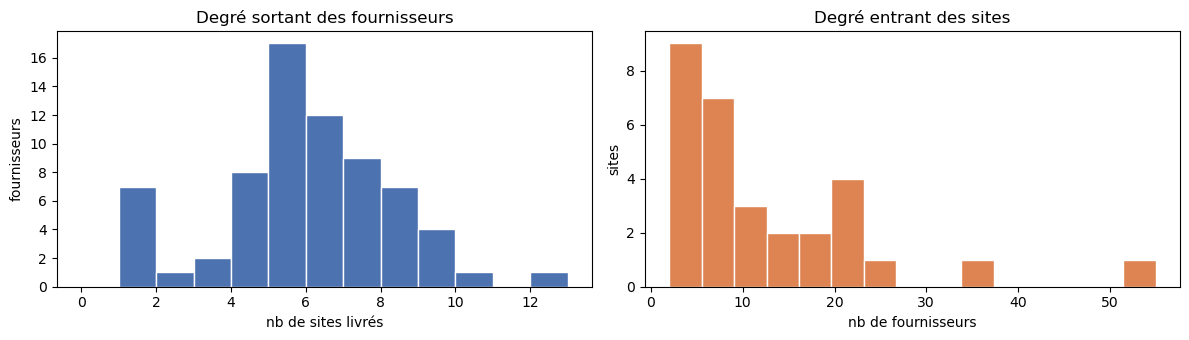

In [37]:
import networkx as nx

flux = gr.groupby(["supplier_partner_code", "receiving_facility_code"]).size().reset_index(name="poids")
G = nx.DiGraph()
for _, r in flux.iterrows():
    G.add_edge(r.supplier_partner_code, r.receiving_facility_code, weight=r.poids)
n, m = G.number_of_nodes(), G.number_of_edges()
fournisseurs = set(flux.supplier_partner_code); sites = set(flux.receiving_facility_code)
print(f"N = {n} nœuds ({len(fournisseurs)} fournisseurs, {len(sites)} sites), L = {m} liens")
print(f"Densité (graphe biparti : L / (nb fournisseurs × nb sites)) = {m / (len(fournisseurs) * len(sites)):.3f}")

deg_out = pd.Series({f: G.out_degree(f) for f in fournisseurs}).sort_values(ascending=False)
deg_in = pd.Series({s: G.in_degree(s) for s in sites}).sort_values(ascending=False)
force_in = pd.Series({s: G.in_degree(s, weight="weight") for s in sites}).sort_values(ascending=False)
print("\nDegré sortant des fournisseurs (nb de sites livrés) : médiane", deg_out.median(), "| max",
      deg_out.idxmax(), deg_out.max())
print("Degré entrant des sites (nb de fournisseurs) — 6 premiers :", deg_in.head(6).to_dict())
print("Force entrante des sites (nb de réceptions) — 6 premiers :", force_in.head(6).to_dict())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(deg_out, bins=range(0, deg_out.max() + 2), color="#4C72B0", edgecolor="white")
axes[0].set(title="Degré sortant des fournisseurs", xlabel="nb de sites livrés", ylabel="fournisseurs")
axes[1].hist(deg_in, bins=15, color="#DD8452", edgecolor="white")
axes[1].set(title="Degré entrant des sites", xlabel="nb de fournisseurs", ylabel="sites")
plt.tight_layout(); plt.show()

In [38]:
# Le fournisseur Meridian (BP-30078) : à quels sites livre-t-il ?
mer = flux[flux.supplier_partner_code == "BP-30078"].sort_values("poids", ascending=False)
mer = mer.merge(fa[["facility_code", "facility_name", "site_groupe_10"]], left_on="receiving_facility_code",
                right_on="facility_code")
print(mer[["receiving_facility_code", "facility_name", "site_groupe_10", "poids"]].to_string(index=False))
print(f"\nPart des livraisons de Meridian vers les sites du groupe des 10 : "
      f"{mer[mer.site_groupe_10 == 1].poids.sum() / mer.poids.sum():.0%}")

receiving_facility_code                      facility_name  site_groupe_10  poids
               FCL-1007  Asterion Avelora Executive Clinic               1     54
               FCL-1019    Meridian Avelora Transfer Annex               1     28
               FCL-1010   Asterion Central Clinical Campus               1     14
               FCL-1030 Kintara Cave Authority Field Depot               1      7
               FCL-1020       Meridian Tembara Coastal Hub               1      4
               FCL-1005    Tembara Customs Inspection Yard               0      1
               FCL-1015 Threshold Earth Avelora Laboratory               1      1

Part des livraisons de Meridian vers les sites du groupe des 10 : 99%


Le siège de Meridian a 55 fournisseurs alors que c'est un bureau. Meridian livre à 99 % le groupe des 10, surtout les cliniques Asterion.

### 7.2 Nœuds centraux et communautés

On passe le graphe en non orienté (un lien = une relation commerciale) pour calculer la betweenness, qui dit si un nœud sert de pont, et la closeness. Ensuite on cherche des communautés avec Louvain.

On a préféré Louvain à Girvan-Newman parce que Girvan-Newman recalcule tout à chaque lien supprimé, ce qui est très lent, et ne prend pas en compte les poids. Louvain optimise directement la modularité, il est rapide et utilise les poids. On fixe la graine pour avoir toujours le même résultat.

In [39]:
Gu = G.to_undirected()
btw = pd.Series(nx.betweenness_centrality(Gu)).sort_values(ascending=False)
clo = pd.Series(nx.closeness_centrality(Gu)).sort_values(ascending=False)
print("Betweenness — 8 nœuds les plus « ponts » :", btw.head(8).round(3).to_dict())
print("Closeness — 5 nœuds les plus centraux :", clo.head(5).round(3).to_dict())

communautes = nx.community.louvain_communities(Gu, weight="weight", seed=0)
Q = nx.community.modularity(Gu, communautes, weight="weight")
print(f"\nLouvain : {len(communautes)} communautés, modularité Q = {Q:.3f}")
groupe10 = set(fa.loc[fa.site_groupe_10 == 1, "facility_code"])
for i, c in enumerate(sorted(communautes, key=len, reverse=True)):
    s = sorted(x for x in c if x.startswith("FCL")); f = [x for x in c if x.startswith("BP")]
    print(f"  C{i}: {len(f):2d} fournisseurs, sites {s} (dont {len(set(s) & groupe10)} du groupe des 10)")

Betweenness — 8 nœuds les plus « ponts » : {'FCL-1011': 0.336, 'FCL-1010': 0.128, 'FCL-1019': 0.103, 'FCL-1007': 0.055, 'FCL-1030': 0.053, 'FCL-1020': 0.045, 'FCL-1029': 0.04, 'BP-30021': 0.036}
Closeness — 5 nœuds les plus centraux : {'FCL-1011': 0.632, 'FCL-1010': 0.508, 'BP-30080': 0.476, 'BP-30021': 0.471, 'BP-30009': 0.467}

Louvain : 5 communautés, modularité Q = 0.337
  C0: 17 fournisseurs, sites ['FCL-1003', 'FCL-1005', 'FCL-1006', 'FCL-1014', 'FCL-1017', 'FCL-1018', 'FCL-1020', 'FCL-1021', 'FCL-1030'] (dont 2 du groupe des 10)
  C1: 19 fournisseurs, sites ['FCL-1004', 'FCL-1011', 'FCL-1013', 'FCL-1015', 'FCL-1022'] (dont 2 du groupe des 10)
  C2: 12 fournisseurs, sites ['FCL-1001', 'FCL-1002', 'FCL-1024', 'FCL-1025', 'FCL-1026', 'FCL-1027', 'FCL-1029'] (dont 2 du groupe des 10)
  C3: 11 fournisseurs, sites ['FCL-1008', 'FCL-1009', 'FCL-1012', 'FCL-1016', 'FCL-1023', 'FCL-1028'] (dont 1 du groupe des 10)
  C4: 10 fournisseurs, sites ['FCL-1007', 'FCL-1010', 'FCL-1019'] (dont 3 

Le siège de Meridian est le principal pont (betweenness 0,34). Louvain (modularité 0,34) isole une communauté Meridian / Asterion.

### 7.3 Le processus commande → réception → inspection → comptabilisation

On construit un journal d'événements avec une trace par commande. On compte combien de fois une étape suit directement une autre, puis on calcule la mesure de dépendance de l'Heuristic Miner : (|u > v| − |v > u|) / (|u > v| + |v > u| + 1).

On a choisi l'Heuristic Miner parce que notre processus est court et propre, et qu'un graphe filtré par un seuil de dépendance se lit facilement. Des méthodes comme l'Inductive Miner ou le Fuzzy Miner sont faites pour de gros journaux désordonnés, ce serait trop lourd ici. La formule tient en quelques lignes, donc on n'a pas eu besoin de `pm4py`.

In [40]:
po_all = pd.read_csv(DATA / "purchase_order_lines.csv", dtype=str).apply(lambda s: s.str.strip()).drop_duplicates()
po_all["order_status"] = po_all.order_status.str.lower()
recu = gr.set_index("purchase_order_number")

traces = []
for _, r in po_all.iterrows():
    t = ["DEBUT", "commande"]
    if r.purchase_order_number in recu.index:
        x = recu.loc[r.purchase_order_number]
        t.append("reception_incomplete" if x.incomplete else "reception_complete")
        t.append("inspection_" + x.inspection_status)
        t.append("posted" if x.receipt_status == "posted" else "quality_hold")
    else:
        t.append("commande_" + r.order_status)
    traces.append(tuple(t + ["FIN"]))

variantes = pd.Series(traces).value_counts()
print(f"{len(traces)} traces, {len(variantes)} variantes ; les 8 plus fréquentes :")
for v, c in variantes.head(8).items():
    print(f"  {c:4d}  " + " → ".join(v[1:-1]))

df_pairs = pd.Series([(a, b) for t in traces for a, b in zip(t, t[1:])]).value_counts()
noeuds = sorted({x for t in traces for x in t})
DF = pd.DataFrame(0, index=noeuds, columns=noeuds)
for (a, b), c in df_pairs.items():
    DF.loc[a, b] = c
dep = (DF - DF.T) / (DF + DF.T + 1)
print("\nLiens conservés (dépendance >= 0,9) :")
print(dep.stack()[lambda s: s >= 0.9].round(3).rename("dépendance").to_frame()
      .join(DF.stack().rename("occurrences")).to_string())

650 traces, 11 variantes ; les 8 plus fréquentes :
   448  commande → reception_complete → inspection_accepted → posted
    63  commande → reception_complete → inspection_conditional → posted
    57  commande → reception_incomplete → inspection_accepted → posted
    31  commande → reception_complete → inspection_held → quality_hold
    18  commande → commande_delayed
    14  commande → commande_pending
     8  commande → commande_cancelled
     4  commande → reception_incomplete → inspection_conditional → posted

Liens conservés (dépendance >= 0,9) :
                                               dépendance  occurrences
DEBUT                  commande                     0.998          650
commande               commande_delayed             0.947           18
                       commande_pending             0.933           14
                       reception_complete           0.998          545
                       reception_incomplete         0.985           65
commande_delayed 

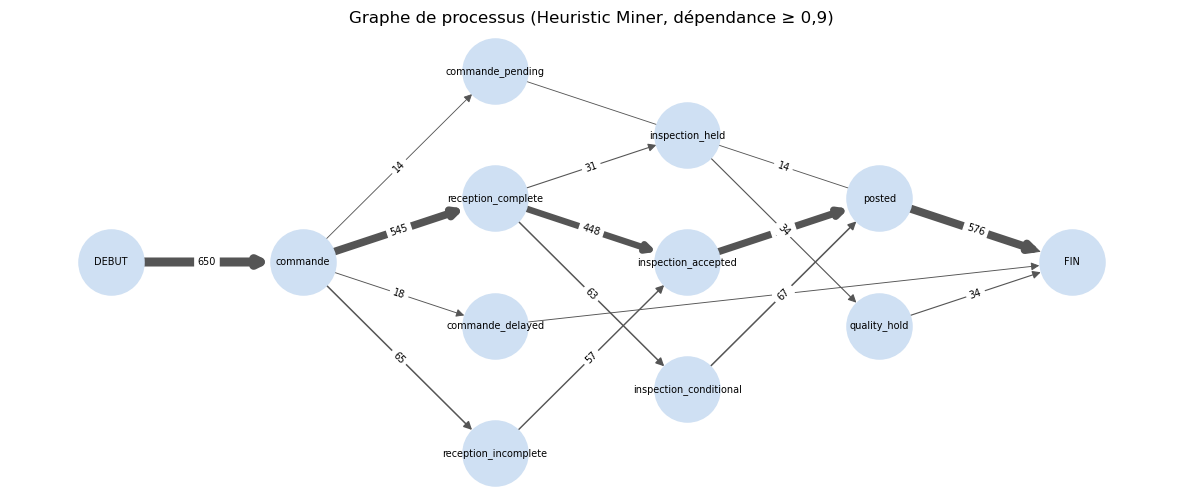

inspection_status  accepted  conditional   held  non_renseigne
incomplete                                                    
complète              0.822        0.116  0.057          0.006
incomplète            0.877        0.062  0.046          0.015


In [41]:
# Représentation du graphe de processus (liens de dépendance >= 0,9, épaisseur = occurrences)
P = nx.DiGraph()
for (a, b), d in dep.stack()[lambda s: s >= 0.9].items():
    P.add_edge(a, b, w=DF.loc[a, b])
couches = {"DEBUT": 0, "commande": 1, "reception_complete": 2, "reception_incomplete": 2, "commande_cancelled": 2,
           "commande_delayed": 2, "commande_pending": 2, "inspection_accepted": 3, "inspection_conditional": 3,
           "inspection_held": 3, "inspection_non_renseigne": 3, "posted": 4, "quality_hold": 4, "FIN": 5}
for nd in P.nodes:
    P.nodes[nd]["layer"] = couches.get(nd, 3)
pos = nx.multipartite_layout(P, subset_key="layer")
fig, ax = plt.subplots(figsize=(15, 6))
w = np.array([P.edges[e]["w"] for e in P.edges])
nx.draw_networkx(P, pos, ax=ax, node_color="#cfe0f3", node_size=2200, font_size=7,
                 width=0.5 + 6 * w / w.max(), arrowsize=12, edge_color="#555")
nx.draw_networkx_edge_labels(P, pos, edge_labels={e: P.edges[e]["w"] for e in P.edges}, font_size=7, ax=ax)
ax.set_title("Graphe de processus (Heuristic Miner, dépendance ≥ 0,9)"); ax.axis("off"); plt.show()

print(pd.crosstab(gr.incomplete.map({0: "complète", 1: "incomplète"}), gr.inspection_status, normalize="index")
      .round(3).to_string())

Le chemin principal est commande → réception → inspection acceptée → comptabilisée. Une réception incomplète est presque toujours acceptée quand même (57 sur 65) : aucune étape ne traite le manque.

---
## Synthèse

Après le nettoyage, on a 610 réceptions. 65 d'entre elles (10,7 %) sont incomplètes, alors que les commandes sont marquées comme soldées.

Le regroupement montre que les réceptions incomplètes forment un groupe à part, qui n'est pas lié au retard.

Les règles d'association font ressortir un circuit Meridian → cliniques Asterion (lift jusqu'à 94). Les manques viennent surtout des autres transporteurs.

Dans le réseau, le siège de Meridian est au centre, et le processus montre qu'aucune étape ne traite les manques.

Les données sont déclarées par Meridian et sûrement synthétiques, donc ce sont des pistes plutôt que des preuves.